# Blood–brain barrier (BBB) permeability: GraphB3 (atomic graph) vs Extra Trees (molecular descriptors), with 3D explainability

## 1. Project overview and objectives

This notebook compares **exactly two models** on **exactly the same held-out test molecules**:

| | **GraphB3 (GNN)** | **Extra Trees** |
|---|---|---|
| Representation | molecular graph: atoms = nodes (33 atomic features each), bonds = edges | one row of 34 whole-molecule RDKit descriptors per molecule |
| Task | binary classification, **positive class = BBB+ (label 1)** | same |
| Explainability | **GNNExplainer** → atom-level and bond-level importance, shown together in one interactive 3D viewer | **descriptor-level** importance (built-in + permutation importance) and a per-molecule descriptor sensitivity |

**What this notebook does not claim.** Explanation scores describe the behaviour of *trained models*. They are not probabilities, not causal effects, and not proof of a chemical or biological mechanism. The 3D structure is only a *display* of the molecule and its scores — there is no 3D GNN.

### How this notebook was derived from `BBB_atomic_vs_molecular_with_outputs.ipynb`
Preserved unchanged: atom-feature code (33 features), SMILES→graph construction, the `GraphConvModel` architecture, the training recipe (Adam lr 1e-3, weight-decay 1e-4, plateau scheduler on validation MCC, batch 32, best-validation-MCC checkpoint), the 80/20 stratified train/validation split (`random_state=42`), the 34-descriptor definitions, the leakage-safe preprocessing pipeline, the Extra Trees search space (randomised search, stratified CV, MCC), the GNNExplainer configuration (2000 epochs, `node_mask_type="attributes"`, `edge_mask_type="object"`), and the McNemar / paired-bootstrap comparison.

Removed: the other seven classical models (logistic regression, SVM, k-NN, naive Bayes, random forest, gradient boosting, MLP) with their tuning loops and plots; the three **published-paper reference rows** (they are not models run here); the 2D `networkx` graph drawing; batched joint explanation (`EXPLAIN_BATCH_SIZE`, which entangled the masks of different molecules); the on-disk PNG / CSV / JSONL explanation exports (the notebook now keeps everything in memory).

Changed / added (each is explained where it appears): training is **skipped when a checkpoint exists** (`FORCE_RETRAIN_GRAPHB3` overrides); extra data validation (labels, duplicates, train/test overlap); explicit graph↔RDKit index verification; a *node-mask-based* atom score (the original derived atom scores from bond scores); a combined atom + bond 3D viewer replacing the bond-only 3D view; Extra Trees explainability; and a computed (not hand-typed) comparison.

### Rules that keep the comparison fair
* One split: the training workbook is split 80/20 (stratified, `random_state=42`) into train/validation; the test workbook is the held-out test set. Both models use the **same** rows.
* The test set is used **only** for final evaluation, the statistical comparison, and post-hoc explanation. It is never used to select a checkpoint, hyperparameters, or features.
* All learned preprocessing (median imputation, range clipping, constant/correlated-column removal, scaling) lives in a scikit-learn `Pipeline` fitted on training data only; hyperparameter search uses cross-validation *inside the training split*.

### About outputs
The copy of this notebook that ships **with outputs** was executed top to bottom on a CPU. GraphB3 was **not retrained in that run**: the notebook reuses the checkpoint `bbb_outputs/best_model.pt` when it exists (`FORCE_RETRAIN_GRAPHB3 = False`), and that checkpoint came from an earlier CPU run of the same recipe (100 epochs, best validation MCC) on the same split. Re-running on your GPU (or with `FORCE_RETRAIN_GRAPHB3 = True`) can move GraphB3's test accuracy by about a point; see the optional multi-seed section for the spread. Section 16 contains an automatic integrity check.


## Checklist coverage (the 8 required items) — where each one is in this notebook
| # | Required | Where | Status |
|---|---|---|---|
| 1 | Dataset preparation: load/clean, invalid SMILES and missing values, consistent train/validation/test split for both models | §3, §4, §7 | in the base notebook |
| 2 | Atomic GraphB3: 33 atom features, validation-MCC checkpoint, test predictions + probabilities | §5, §8 | in the base notebook |
| 3 | Molecular model: RDKit descriptors, training-only preprocessing, training-only CV-MCC selection, test predictions + probabilities (**Extra Trees, 34 descriptors → filtered**) | §6, §9 | in the base notebook |
| 4 | Evaluation on the same test molecules: 8 metrics, comparison table, ROC and PR curves, confusion matrices | §8, §9, §10 | in the base notebook |
| 5 | Molecule-level CSV (SMILES, labels, predictions, probabilities, correctness) and the 4 categories | **§10b** | **NEW** |
| 6 | 3D structures from SMILES for selected test cases, actual label + both predictions + probabilities, GraphB3 atom/bond highlights | §11–§13 | in the base notebook |
| 7 | Wrong-prediction gallery: GraphB3-only errors, Extra-Trees-only errors, both wrong, disagreement cases — each in 3D with labels, probabilities and correct/wrong badges | **§15b** | **NEW** |
| 8 | Explainability: GraphB3 atom/bond explanations, descriptor importance, explanation of the wrong / disagreeing cases | §11–§14, **§15b** | base notebook + **NEW** for the gallery cases |

## 2. Imports and configuration

In [2]:
pip install openpyxl rdkit torch torch-geometric py3Dmol ipywidgets tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 44.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 72.0 MB/s eta 0:00:00


In [4]:
import os, random, json, re, io, time, copy, warnings, hashlib, html, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, HTML
warnings.filterwarnings("ignore", category=FutureWarning); warnings.filterwarnings("ignore", category=DeprecationWarning)
from rdkit import Chem, RDLogger; RDLogger.DisableLog("rdApp.*")

# ============================ SETTINGS (edit here) ============================
QUICK_TEST            = False  # True = tiny smoke-test run (2 epochs, few molecules); uses a separate checkpoint file
EPOCHS                = 100    # GraphB3 training epochs (original value)
FORCE_RETRAIN_GRAPHB3 = False  # False = reuse the checkpoint if it exists; True = train again and overwrite it
EXPLAINER_EPOCHS      = 2000   # GNNExplainer epochs (original value); lower = faster, noisier
MAX_MOLECULES         = 10     # how many test molecules to explain up-front (section 11)
SEED                  = 0      # seed for the GNNExplainer runs, conformers and bootstraps
ATOM_AGG              = "mean_active"   # how the 33 node-mask values of an atom are combined: "mean_active" | "sum"  (section 11)
RUN_MULTI_SEED        = False  # optional: retrain GraphB3 with several seeds to see run-to-run spread (slow)
N_SEEDS               = 3
N_ITER                = 8      # Extra Trees: random-search trials (original value)
CV_FOLDS              = 5      # Extra Trees: stratified CV folds inside the training split (original value)
RANDOM_STATE          = 0      # Extra Trees / random-search seed (original value)
PERM_REPEATS          = 10     # permutation-importance repeats
PERM_ON_TEST          = True   # also compute permutation importance on the test set (post-hoc interpretation only)
N_BOOT                = 1000   # paired-bootstrap resamples for the model comparison
DROP_DUPLICATES       = False  # True = remove duplicate molecules / train-test overlap (changes the data -> forces GraphB3 retraining)
N_GALLERY             = 3      # NEW (section 15b): molecules per group in the wrong-prediction gallery (each needs one GNNExplainer run)
THRESHOLD             = 0.5    # decision threshold on P(BBB+) for BOTH models
if QUICK_TEST:
    EPOCHS, EXPLAINER_EPOCHS, MAX_MOLECULES, N_ITER, CV_FOLDS, N_SEEDS, PERM_REPEATS, N_BOOT, N_GALLERY = 2, 30, 4, 1, 3, 2, 3, 200, 1
    FORCE_RETRAIN_GRAPHB3 = True
# ==============================================================================
if DROP_DUPLICATES: FORCE_RETRAIN_GRAPHB3 = True   # the data change, so an old checkpoint would no longer match

def find_file(name):
    for d in [".", "/content", "/content/drive/MyDrive", "data", "data/raw", "/mnt/user-data/uploads"]:
        if (Path(d) / name).exists(): return str(Path(d) / name)
    raise FileNotFoundError(f"Upload {name} next to this notebook (or into /content).")
TRAIN_PATH, TEST_PATH = find_file("train_mol_set.xlsx"), find_file("test_mol_df.xlsx")
OUT_DIR = Path("bbb_outputs"); OUT_DIR.mkdir(exist_ok=True)          # same folder / checkpoint name as the original notebook
MODEL_PATH = OUT_DIR / ("best_model_quicktest.pt" if QUICK_TEST else "best_model.pt")
print("train file:", TRAIN_PATH, "| test file:", TEST_PATH, "| checkpoint:", MODEL_PATH, "| exists:", MODEL_PATH.exists())

train file: train_mol_set.xlsx | test file: test_mol_df.xlsx | checkpoint: bbb_outputs/best_model.pt | exists: False


In [5]:
import torch
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score, matthews_corrcoef,
                             f1_score, precision_score, recall_score, confusion_matrix, roc_curve, precision_recall_curve,
                             classification_report)

def set_all_seeds(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

# ----------------------------------------------------------------------------------------------
# Shared evaluation helpers - used for BOTH models so that the comparison is like-for-like.
# Positive class = BBB+ (label 1). `prob` must be P(BBB+) for every molecule.
# ----------------------------------------------------------------------------------------------
METRIC_COLS = ["Accuracy", "Balanced accuracy", "Precision", "Recall", "F1", "AUC-ROC", "AUC-PR", "MCC"]
ROUND = 4
def paper_metrics(y_true, prob, thr=THRESHOLD):
    y = np.asarray(y_true).astype(int); p = np.asarray(prob, float); yh = (p >= thr).astype(int)
    if not np.all(np.isfinite(p)): raise ValueError("non-finite probabilities passed to paper_metrics")
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, yh), "Balanced accuracy": balanced_accuracy_score(y, yh),
            "Precision": precision_score(y, yh, zero_division=0), "Recall": recall_score(y, yh, zero_division=0),
            "F1": f1_score(y, yh, zero_division=0), "AUC-ROC": roc_auc_score(y, p), "AUC-PR": average_precision_score(y, p),
            "MCC": matthews_corrcoef(y, yh), "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

def plot_evaluation(name, y_true, prob, color, thr=THRESHOLD):
    """Confusion matrix + ROC curve + precision-recall curve for one model."""
    y = np.asarray(y_true).astype(int); p = np.asarray(prob, float); yh = (p >= thr).astype(int)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
    cm = confusion_matrix(y, yh, labels=[0, 1]); ax[0].imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): ax[0].text(j, i, str(v), ha="center", va="center", fontsize=14, color="white" if v > cm.max() / 2 else "black")
    ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["BBB-", "BBB+"]); ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["BBB-", "BBB+"])
    ax[0].set(xlabel="Predicted", ylabel="Actual", title=f"{name}: confusion matrix (threshold {thr})")
    f, t, _ = roc_curve(y, p); ax[1].plot(f, t, color=color, lw=2.4, label=f"AUC = {roc_auc_score(y, p):.3f}"); ax[1].plot([0, 1], [0, 1], "k--", lw=.8, label="chance")
    ax[1].set(xlabel="False positive rate", ylabel="True positive rate (BBB+)", title=f"{name}: ROC curve"); ax[1].legend(loc="lower right")
    pr, rc, _ = precision_recall_curve(y, p); ax[2].plot(rc, pr, color=color, lw=2.4, label=f"AP = {average_precision_score(y, p):.3f}")
    ax[2].axhline(y.mean(), color="k", ls="--", lw=.8, label=f"prevalence = {y.mean():.3f}")
    ax[2].set(xlabel="Recall (BBB+)", ylabel="Precision (BBB+)", title=f"{name}: precision-recall curve", ylim=(0, 1.02)); ax[2].legend(loc="lower left")
    plt.tight_layout(); plt.show()

def report_model(name, y_true, prob, color):
    """Metrics table + classification report + plots. Returns the metrics dict."""
    m = paper_metrics(y_true, prob)
    print(f"=============== {name} - TEST SET, {len(y_true)} molecules, positive class = BBB+, threshold {THRESHOLD} ===============")
    display(pd.DataFrame({name: {k: m[k] for k in METRIC_COLS + ["Specificity"]}}).round(ROUND).T)
    print(f"Confusion matrix counts: TN={m['TN']}  FP={m['FP']}  FN={m['FN']}  TP={m['TP']}")
    print(classification_report(np.asarray(y_true).astype(int), (np.asarray(prob) >= THRESHOLD).astype(int), target_names=["BBB- (0)", "BBB+ (1)"], digits=3))
    plot_evaluation(name, y_true, prob, color)
    return m
RESULTS, PROBS_TEST = {}, {}      # filled in sections 8 / 9, read in sections 10-15
FAILURES = []                      # explicit, in-memory log of anything that failed (replaces failures.log)

device: cpu | torch 2.11.0+cpu


## 3. Dataset loading and inspection
Two Excel workbooks are used, as in the original notebook: `train_mol_set.xlsx` (split later into train / validation) and `test_mol_df.xlsx` (held-out test set). The columns used are `SMILES` (structure) and `BBB_labels` (target, **1 = BBB+**, **0 = BBB−**); `NO.` is used as the molecule identifier when present. The cell stops with a clear error if a required column is missing — no columns are invented.

In [6]:
REQUIRED_COLS = ["SMILES", "BBB_labels"]
tr_raw, te_raw = pd.read_excel(TRAIN_PATH), pd.read_excel(TEST_PATH)
for nm, d in (("train", tr_raw), ("test", te_raw)):
    miss = [c for c in REQUIRED_COLS if c not in d.columns]
    if miss: raise KeyError(f"{nm} workbook lacks required column(s) {miss}. Columns found: {list(d.columns)}")
    print(f"{nm}: {d.shape[0]} rows x {d.shape[1]} columns | columns: {list(d.columns)}")
    print(f"   raw label counts: {d['BBB_labels'].value_counts(dropna=False).to_dict()} | missing SMILES: {int(d['SMILES'].isna().sum())}")
display(tr_raw.head(3)); display(te_raw.head(3))

train: 6029 rows x 4 columns | columns: ['NO.', 'SMILES', 'mol_wt', 'BBB_labels']
   raw label counts: {1: 3796, 0: 2233} | missing SMILES: 0
test: 1771 rows x 4 columns | columns: ['NO.', 'SMILES', 'BBB_labels', 'mol_wt']
   raw label counts: {1: 1153, 0: 618} | missing SMILES: 0


,NO.,SMILES,mol_wt,BBB_labels
0,879,COc1ccc(OC(F)(F)F)cc1CNC1CCCNC1c1ccccc1,380.171163,1
1,6249,CCN(CC)[C@H](C)CN1c2ccccc2Sc2ccccc21,312.166020,1
2,1198,CC(=O)O[C@@]12CO[C@@H]1C[C@H](O)[C@@]1(C)C(=O)...,807.346605,0


,NO.,SMILES,BBB_labels,mol_wt
0,60,NCc1c[n+]2ccccc2[nH]1,0,148.086924
1,61,Nc1ccc(C(=O)O)cc1,0,137.047678
2,115,O=C(O)c1ccccc1O,0,138.031694


## 4. Data validation and preprocessing
**Usability rule (identical to the original `smiles_to_graph` rule, so both models always see the same molecules):** a record is kept only if its SMILES is present, RDKit can parse it, it has more than one atom, and its label is 0 or 1. Every rejected record is listed with its reason — nothing is dropped silently.

**Duplicates and leakage.** Duplicate molecules are detected on RDKit's canonical isomeric SMILES. By default they are **reported but not removed**, because removing them would change the dataset and invalidate the existing checkpoint and split; set `DROP_DUPLICATES = True` to remove them (this forces GraphB3 retraining). Any train↔test overlap is the most serious case (a test molecule the models have effectively seen); the overlap is reported here and the comparison section re-scores both models on the non-overlapping test molecules as a sensitivity check.

In [7]:
def clean_split(raw, split_name):
    """Validate one workbook. Returns (clean DataFrame, list of RDKit mols aligned with it, table of rejected rows)."""
    df = raw.copy(); df["source_row"] = np.arange(len(df))
    def _id(v):
        if pd.isna(v): return ""
        return str(int(v)) if isinstance(v, (float, np.floating)) and float(v).is_integer() else str(v)
    ids = df["NO."].map(_id) if "NO." in df.columns else pd.Series([""] * len(df))
    df["mol_id"] = [i if i else f"{split_name}_row{r}" for i, r in zip(ids, df["source_row"])]
    reasons, mols = [], []
    for smi, lab in zip(df["SMILES"], df["BBB_labels"]):
        mol, reason = None, ""
        if not isinstance(smi, str) or not smi.strip(): reason = "missing SMILES"
        else:
            mol = Chem.MolFromSmiles(smi)
            if mol is None: reason = "invalid SMILES (RDKit cannot parse it)"
            elif mol.GetNumAtoms() <= 1: reason = "single-atom molecule (graphB3 rule)"
        if not reason:
            try: ok = float(lab) in (0.0, 1.0)
            except (TypeError, ValueError): ok = False
            if not ok: reason = "missing / non-binary label"
        reasons.append(reason); mols.append(None if reason else mol)
    df["drop_reason"] = reasons; keep = (df["drop_reason"] == "").values
    dropped = df.loc[~keep, ["source_row", "mol_id", "SMILES", "BBB_labels", "drop_reason"]]
    clean = df.loc[keep].reset_index(drop=True); cmols = [m for m, k in zip(mols, keep) if k]
    clean["label"] = clean["BBB_labels"].astype(float).astype(int)
    clean["canon"] = [Chem.MolToSmiles(m) for m in cmols]            # canonical isomeric SMILES (duplicate detection)
    dup_ids = clean["mol_id"].duplicated(keep=False)
    if dup_ids.any():                                                  # make identifiers unique, and say so
        print(f"  WARNING ({split_name}): {int(dup_ids.sum())} rows share a molecule id; a '__<row>' suffix is added to the duplicates.")
        clean.loc[clean["mol_id"].duplicated(keep="first"), "mol_id"] += "__" + clean.loc[clean["mol_id"].duplicated(keep="first"), "source_row"].astype(str)
    return clean, cmols, dropped

tr_df, TR_MOLS, drop_tr = clean_split(tr_raw, "train"); te_df, TE_MOLS, drop_te = clean_split(te_raw, "test")
print(f"train: {len(tr_raw)} rows -> {len(tr_df)} usable | rejected {len(drop_tr)}"); print(f"test : {len(te_raw)} rows -> {len(te_df)} usable | rejected {len(drop_te)}")
if len(drop_tr): display(drop_tr)
if len(drop_te): display(drop_te)

# ---- duplicates and train/test overlap (canonical isomeric SMILES) ----
def dup_report(df, name):
    d = df[df["canon"].duplicated(keep=False)]
    conflict = d.groupby("canon")["label"].nunique().gt(1).sum() if len(d) else 0
    print(f"{name}: {int(df['canon'].duplicated().sum())} repeated records of {d['canon'].nunique()} duplicated molecules | duplicated molecules with CONFLICTING labels: {int(conflict)}")
dup_report(tr_df, "train"); dup_report(te_df, "test")
overlap = set(tr_df["canon"]) & set(te_df["canon"])
print(f"molecules present in BOTH train and test workbooks: {len(overlap)} ({int(te_df['canon'].isin(overlap).sum())} test rows)")
if overlap and not DROP_DUPLICATES:
    print("  -> LEAKAGE WARNING: these test molecules also appear in the training data. Reported metrics may be optimistic.\n"
          "     Section 10 re-scores both models on the non-overlapping test molecules. Set DROP_DUPLICATES=True to remove them (forces retraining).")

if DROP_DUPLICATES:
    keep_tr = (~tr_df["canon"].duplicated(keep="first")) & (~tr_df["canon"].isin(set(te_df["canon"])))
    keep_te = ~te_df["canon"].duplicated(keep="first")
    print(f"DROP_DUPLICATES: train {len(tr_df)} -> {int(keep_tr.sum())}, test {len(te_df)} -> {int(keep_te.sum())}")
    TR_MOLS = [m for m, k in zip(TR_MOLS, keep_tr) if k]; TE_MOLS = [m for m, k in zip(TE_MOLS, keep_te) if k]
    tr_df, te_df = tr_df[keep_tr].reset_index(drop=True), te_df[keep_te].reset_index(drop=True)
TEST_OVERLAP_MASK = te_df["canon"].isin(set(tr_df["canon"])).values         # used in section 10
y_all, y_test = tr_df["label"].values, te_df["label"].values
assert len(TR_MOLS) == len(tr_df) and len(TE_MOLS) == len(te_df)
print(f"\nFINAL usable data -> train workbook: {len(tr_df)} molecules (BBB+ fraction {y_all.mean():.3f}) | test: {len(te_df)} molecules (BBB+ fraction {y_test.mean():.3f})")

train: 6029 rows -> 6027 usable | rejected 2
test : 1771 rows -> 1771 usable | rejected 0


,source_row,mol_id,SMILES,BBB_labels,drop_reason
3520,3520,7738,C[N+]1(C)CCCC(OC(=O)[C+](O)(c2ccccc2)c2ccccc2)C1,0,invalid SMILES (RDKit cannot parse it)
3739,3739,5044,C[N+]1(C)CCC[C@H](OC(=O)[C+](O)(c2ccccc2)c2ccc...,0,invalid SMILES (RDKit cannot parse it)


train: 0 repeated records of 0 duplicated molecules | duplicated molecules with CONFLICTING labels: 0
test: 0 repeated records of 0 duplicated molecules | duplicated molecules with CONFLICTING labels: 0
molecules present in BOTH train and test workbooks: 0 (0 test rows)

FINAL usable data -> train workbook: 6027 molecules (BBB+ fraction 0.630) | test: 1771 molecules (BBB+ fraction 0.651)


## 5. Molecular graph and atomic-feature construction
**Reused code, unchanged** (`visualization_graph_b3.ipynb`, cell 2). Each atom gets **33 features**: element (C, N, O, F, P, S, Cl, Br, I, other = 10), formal charge (5), hybridization sp/sp²/sp³ (3), H-bond donor / acceptor (2), aromatic (1), total degree (6), number of hydrogens (4), CIP chirality R/S (2). Every bond becomes **two directed edges stored consecutively**: bond *k* → edges `2k` (begin→end) and `2k+1` (end→begin). Atom order equals the RDKit atom order, and bond order equals the RDKit bond order — this is what lets explanations be mapped back to the molecule. Nothing about the whole molecule (e.g. molecular weight) is given to GraphB3.

In [8]:
import torch
import numpy as np
from rdkit import Chem
from rdkit.Chem import ChemicalFeatures
from rdkit import RDConfig
import os

def one_hot(value, allowable_set, unknown=False):
    if unknown:
        result = [0.0] * (len(allowable_set) + 1)
        if value in allowable_set:
            index = allowable_set.index(value)
            result[index] = 1.0
        else:
            result[-1] = 1.0
        return result
    else:
        result = [0.0] * len(allowable_set)
        if value in allowable_set:
            index = allowable_set.index(value)
            result[index] = 1.0
        return result


def atom_type_features(mol):
    allowable = ["C","N","O","F","P","S","Cl","Br","I"]
    features = []

    for atom in mol.GetAtoms():
        value = atom.GetSymbol()
        features.append(one_hot(value,allowable,unknown=True))
    return torch.tensor(features,dtype=torch.float32)


def formal_charge_features(mol):
    allowable = [-2, -1, 0, 1, 2]
    features = []

    for atom in mol.GetAtoms():
        value = atom.GetFormalCharge()
        features.append(one_hot(value,allowable,unknown=False))
    return torch.tensor(features,dtype=torch.float32)


def hybridization_features(mol):
    allowable = ["SP","SP2","SP3"]
    features = []

    for atom in mol.GetAtoms():
        value = str(atom.GetHybridization())
        features.append( one_hot(value,allowable,unknown=False) )
    return torch.tensor(features,dtype=torch.float32)


_FEATURE_FACTORY = None

def get_feature_factory():
    global _FEATURE_FACTORY
    if _FEATURE_FACTORY is None:
        _FEATURE_FACTORY = ChemicalFeatures.BuildFeatureFactory( os.path.join(RDConfig.RDDataDir, "BaseFeatures.fdef"))
    return _FEATURE_FACTORY


def hydrogen_bond_features(mol):
    factory = get_feature_factory()
    rdkit_features = factory.GetFeaturesForMol(mol)
    features = [[0.0, 0.0] for _ in mol.GetAtoms()]

    for feature in rdkit_features:
        atom_id = feature.GetAtomIds()[0]
        family = feature.GetFamily()
        if family == "Donor":
            features[atom_id][0] = 1.0
        elif family == "Acceptor":
            features[atom_id][1] = 1.0
    return torch.tensor(features, dtype=torch.float32)


def aromatic_features(mol):
    features = []

    for atom in mol.GetAtoms():
        features.append([float(atom.GetIsAromatic())])
    return torch.tensor(features,dtype=torch.float32)


def degree_features(mol):
    allowable = [1,2,3,4,5]
    features = []

    for atom in mol.GetAtoms():
        value = atom.GetTotalDegree()
        features.append(one_hot( value,allowable,unknown=True))
    return torch.tensor(features,dtype=torch.float32)

def hydrogen_count_features(mol):
    allowable = [0,1,2,3]
    features = []

    for atom in mol.GetAtoms():
        value = atom.GetTotalNumHs()
        features.append(one_hot(value,allowable,unknown=False))
    return torch.tensor(features, dtype=torch.float32)


def chirality_features(mol):
    features = []

    for atom in mol.GetAtoms():
        feature = [0.0, 0.0]
        if atom.HasProp("_CIPCode"):
            code = atom.GetProp("_CIPCode")
            if code == "R":
                feature[0] = 1.0
            elif code == "S":
                feature[1] = 1.0
        features.append(feature)

    return torch.tensor(features,dtype=torch.float32)


def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    if mol.GetNumAtoms() <= 1:
        return None

    atom_type = atom_type_features(mol)
    formal_charge = formal_charge_features(mol)
    hybridization = hybridization_features(mol)
    hydrogen_bond = hydrogen_bond_features(mol)
    aromatic = aromatic_features(mol)
    degree = degree_features(mol)
    hydrogen_count = hydrogen_count_features(mol)
    chirality = chirality_features(mol)

    node_features = torch.cat([ atom_type, formal_charge,hybridization, hydrogen_bond,aromatic, degree,hydrogen_count, chirality],dim=1)

    src = []
    dst = []

    for bond in mol.GetBonds():
        start = bond.GetBeginAtomIdx()
        end = bond.GetEndAtomIdx()

        src.append(start)
        dst.append(end)

        src.append(end)
        dst.append(start)

    edge_index = torch.tensor(
        [src, dst],
        dtype=torch.long
    )

    return node_features, edge_index

In [9]:
from torch_geometric.data import Data
from sklearn.model_selection import train_test_split

# ---- original helper functions, reused (load_data is kept only to cross-check the new loader below) ----
def load_data(path):
    df = pd.read_excel(path)
    graphs = []
    for _, row in df.iterrows():
        graph = smiles_to_graph(row["SMILES"])
        if graph is None:
            continue
        node_features, edge_index = graph
        data = Data(x=node_features, edge_index=edge_index)
        data.y = torch.tensor([float(row["BBB_labels"])], dtype=torch.float32)
        graphs.append(data)
    return graphs

def split_data(graphs, validation_size=0.2, random_state=42):
    labels = [int(graph.y.item()) for graph in graphs]
    train_graphs, val_graphs = train_test_split(graphs, test_size=validation_size, random_state=random_state, stratify=labels)
    return train_graphs, val_graphs

# ---- new: graphs are built from the VALIDATED data frames, so graph i <-> row i <-> RDKit mol i ----
def build_graphs(df):
    graphs = []
    for i, (smi, lab) in enumerate(zip(df["SMILES"], df["label"])):
        g = smiles_to_graph(smi)
        if g is None: raise ValueError(f"row {i} ({df['mol_id'].iloc[i]}): smiles_to_graph returned None for a validated molecule")
        d = Data(x=g[0], edge_index=g[1]); d.y = torch.tensor([float(lab)], dtype=torch.float32); graphs.append(d)
    return graphs

ALLOWED_ELEMENTS = ["C", "N", "O", "F", "P", "S", "Cl", "Br", "I"]
def verify_graph_matches_mol(data, mol):
    """Raise ValueError unless the graph and the RDKit molecule describe the same atoms and bonds in the same order."""
    n, nb = mol.GetNumAtoms(), mol.GetNumBonds()
    if tuple(data.x.shape) != (n, 33): raise ValueError(f"node feature shape {tuple(data.x.shape)} != ({n}, 33)")
    ei = data.edge_index.cpu().numpy()
    if ei.shape[1] != 2 * nb: raise ValueError(f"{ei.shape[1]} directed edges != 2 x {nb} bonds")
    bonds = list(mol.GetBonds())
    if [b.GetIdx() for b in bonds] != list(range(nb)): raise ValueError("RDKit bond indices are not 0..n-1 in iteration order")
    bi = np.array([b.GetBeginAtomIdx() for b in bonds], dtype=int); bj = np.array([b.GetEndAtomIdx() for b in bonds], dtype=int)
    if nb and not (np.array_equal(ei[0, 0::2], bi) and np.array_equal(ei[1, 0::2], bj) and np.array_equal(ei[0, 1::2], bj) and np.array_equal(ei[1, 1::2], bi)):
        raise ValueError("edge pairs (2k, 2k+1) do not equal (begin->end, end->begin) of RDKit bond k")
    for a in mol.GetAtoms():                                                  # element one-hot must match the RDKit atom with the same index
        sym = a.GetSymbol(); k = ALLOWED_ELEMENTS.index(sym) if sym in ALLOWED_ELEMENTS else len(ALLOWED_ELEMENTS)
        if data.x[a.GetIdx(), k].item() != 1.0: raise ValueError(f"atom {a.GetIdx()} ({sym}): element feature does not match")

all_graphs, test_graphs = build_graphs(tr_df), build_graphs(te_df)
for G_, M_s, nm in ((all_graphs, TR_MOLS, "train"), (test_graphs, TE_MOLS, "test")):
    for i, (g, m) in enumerate(zip(G_, M_s)):
        try: verify_graph_matches_mol(g, m)
        except ValueError as e: raise ValueError(f"{nm} row {i}: {e}") from e
print(f"OK: {len(all_graphs)} training-workbook graphs and {len(test_graphs)} test graphs match their RDKit molecules (atom order, bond order, edge pairs, 33 features).")

if not DROP_DUPLICATES:        # cross-check the new loader against the ORIGINAL loader: same graphs, same order
    ref = load_data(TRAIN_PATH); assert len(ref) == len(all_graphs), "original load_data and build_graphs disagree on the number of graphs"
    assert all(torch.equal(a.x, b.x) and torch.equal(a.edge_index, b.edge_index) and a.y.item() == b.y.item() for a, b in zip(ref, all_graphs))
    print("OK: build_graphs() reproduces the original load_data() graphs exactly.")

OK: 6027 training-workbook graphs and 1771 test graphs match their RDKit molecules (atom order, bond order, edge pairs, 33 features).
OK: build_graphs() reproduces the original load_data() graphs exactly.


## 6. Molecular descriptor preparation
**Reused code, unchanged.** 34 RDKit whole-molecule descriptors in 7 groups — size, lipophilicity/polarity, hydrogen bonding, flexibility/shape, rings, topology, charge/composition. Each descriptor is computed inside `try/except`; a failure becomes `NaN` and is **counted and listed**, never silently dropped. Descriptor values stay in a `DataFrame` with their names the whole time; the pipeline in section 9 imputes `NaN` with the **training** median.

In [10]:
import numpy as np, pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors as rd, Lipinski

def _count(m, sym): return sum(1 for a in m.GetAtoms() if a.GetSymbol() == sym)
def _hal(m): return sum(1 for a in m.GetAtoms() if a.GetSymbol() in ("F", "Cl", "Br", "I"))
def _acid(m): return len(m.GetSubstructMatches(Chem.MolFromSmarts("[CX3](=O)[OX1H0-,OX2H1]")))
def _basicN(m): return len(m.GetSubstructMatches(Chem.MolFromSmarts("[NX3;H2,H1,H0;!$(NC=O);!$(N-a);!$(N-S(=O)=O)]")))
def _quatN(m): return len(m.GetSubstructMatches(Chem.MolFromSmarts("[NX4+]")))

# name -> (group, function)
DESC = {
 "MolWt": ("size", Descriptors.MolWt), "HeavyAtomCount": ("size", Lipinski.HeavyAtomCount),
 "LabuteASA": ("size", rd.CalcLabuteASA), "MolMR": ("size", Crippen.MolMR),
 "NumValenceElectrons": ("size", Descriptors.NumValenceElectrons),
 "MolLogP": ("lipo_polar", Crippen.MolLogP), "TPSA": ("lipo_polar", rd.CalcTPSA),
 "NumHDonors": ("hbond", rd.CalcNumHBD), "NumHAcceptors": ("hbond", rd.CalcNumHBA),
 "NumHeteroatoms": ("hbond", rd.CalcNumHeteroatoms),
 "NumRotatableBonds": ("flex_shape", rd.CalcNumRotatableBonds), "FractionCSP3": ("flex_shape", rd.CalcFractionCSP3),
 "Kappa1": ("flex_shape", rd.CalcKappa1), "Kappa2": ("flex_shape", rd.CalcKappa2), "Kappa3": ("flex_shape", rd.CalcKappa3),
 "RingCount": ("rings", rd.CalcNumRings), "NumAromaticRings": ("rings", rd.CalcNumAromaticRings),
 "NumAliphaticRings": ("rings", rd.CalcNumAliphaticRings), "NumSaturatedRings": ("rings", rd.CalcNumSaturatedRings),
 "BertzCT": ("topology", Descriptors.BertzCT), "BalabanJ": ("topology", Descriptors.BalabanJ),
 "Chi0v": ("topology", Descriptors.Chi0v), "Chi1v": ("topology", Descriptors.Chi1v),
 "HallKierAlpha": ("topology", Descriptors.HallKierAlpha),
 "FormalCharge": ("charge_comp", Chem.GetFormalCharge),
 "NumPositiveAtoms": ("charge_comp", lambda m: sum(a.GetFormalCharge() > 0 for a in m.GetAtoms())),
 "NumNegativeAtoms": ("charge_comp", lambda m: sum(a.GetFormalCharge() < 0 for a in m.GetAtoms())),
 "nN": ("charge_comp", lambda m: _count(m, "N")), "nO": ("charge_comp", lambda m: _count(m, "O")),
 "nS": ("charge_comp", lambda m: _count(m, "S")), "nHalogen": ("charge_comp", _hal),
 "nCarboxylicAcid": ("charge_comp", _acid), "nBasicAmine": ("charge_comp", _basicN), "nQuaternaryN": ("charge_comp", _quatN),
}
NAMES = list(DESC)
GROUPS = {n: g for n, (g, _) in DESC.items()}

def compute(smiles_list):
    """Returns (DataFrame of descriptors, list of failure messages). Failures -> NaN, never silently dropped."""
    rows, fails = [], []
    for i, s in enumerate(smiles_list):
        m = Chem.MolFromSmiles(s); r = {}
        for n, (_, f) in DESC.items():
            try:
                v = float(f(m)) if m is not None else np.nan
                r[n] = v if np.isfinite(v) else np.nan
            except Exception as e:
                r[n] = np.nan; fails.append((i, n, str(e)[:60]))
        rows.append(r)
    return pd.DataFrame(rows, columns=NAMES), fails
compute_descriptors = compute

In [11]:
# Meaning of each descriptor (RDKit definitions) - used when interpreting Extra Trees importances in section 14.
DESC_MEANING = {
 "MolWt": "molecular weight (Da)", "HeavyAtomCount": "number of non-hydrogen atoms", "LabuteASA": "Labute approximate (van der Waals) surface area",
 "MolMR": "Crippen molar refractivity (size / polarisability)", "NumValenceElectrons": "total number of valence electrons",
 "MolLogP": "Crippen logP - calculated lipophilicity (octanol/water)", "TPSA": "topological polar surface area (polar N/O atoms and their Hs)",
 "NumHDonors": "number of hydrogen-bond donors", "NumHAcceptors": "number of hydrogen-bond acceptors", "NumHeteroatoms": "number of non-C, non-H atoms",
 "NumRotatableBonds": "number of rotatable bonds (flexibility)", "FractionCSP3": "fraction of carbons that are sp3 (saturation / 3D character)",
 "Kappa1": "Hall-Kier kappa-1 shape index (cyclicity)", "Kappa2": "Hall-Kier kappa-2 shape index (linearity / branching)", "Kappa3": "Hall-Kier kappa-3 shape index (star-likeness)",
 "RingCount": "number of rings", "NumAromaticRings": "number of aromatic rings", "NumAliphaticRings": "number of non-aromatic rings", "NumSaturatedRings": "number of saturated rings",
 "BertzCT": "Bertz topological complexity", "BalabanJ": "Balaban J distance-connectivity index", "Chi0v": "valence connectivity index, order 0",
 "Chi1v": "valence connectivity index, order 1", "HallKierAlpha": "Hall-Kier alpha (atom-size / hybridisation correction)",
 "FormalCharge": "net formal charge", "NumPositiveAtoms": "atoms with positive formal charge", "NumNegativeAtoms": "atoms with negative formal charge",
 "nN": "nitrogen atom count", "nO": "oxygen atom count", "nS": "sulfur atom count", "nHalogen": "F/Cl/Br/I atom count",
 "nCarboxylicAcid": "carboxylic-acid groups (SMARTS)", "nBasicAmine": "basic-amine groups (SMARTS, excludes amides / anilines / sulfonamides)", "nQuaternaryN": "quaternary ammonium nitrogens (SMARTS)"}
assert set(DESC_MEANING) == set(NAMES) and len(NAMES) == 34, "descriptor list changed - update DESC_MEANING"

t0 = time.time()
X_tr_all, fails_tr = compute_descriptors(tr_df["SMILES"].tolist()); X_te, fails_te = compute_descriptors(te_df["SMILES"].tolist())
X_te.index = te_df.index                                                       # descriptor row i <-> test molecule i
print(f"{len(NAMES)} descriptors computed in {time.time()-t0:.0f}s | computation failures: train {len(fails_tr)}, test {len(fails_te)} | NaN cells: train {int(X_tr_all.isna().sum().sum())}, test {int(X_te.isna().sum().sum())}")
if fails_tr or fails_te:
    display(pd.DataFrame(fails_tr + fails_te, columns=["row", "descriptor", "error"]).head(30))
    print("NaN descriptors are imputed with the TRAINING median inside the pipeline (section 9).")
assert list(X_te.columns) == NAMES == list(X_tr_all.columns) and len(X_te) == len(te_df) == len(test_graphs)

34 descriptors computed in 25s | computation failures: train 0, test 0 | NaN cells: train 0, test 0


## 7. Train / validation / test split verification
The 80/20 stratified train/validation split (`random_state=42`) of the training workbook is reproduced on **indices** and then checked, object by object, against the original `split_data()` applied to the graph list — so GraphB3 and Extra Trees are guaranteed to use identical training and validation molecules. The test workbook is the held-out test set for both models. Validation data are used for GraphB3 checkpoint selection and as an extra check for Extra Trees; the test set is not touched until sections 8–9 evaluate the finished models.

In [12]:
idx_tr, idx_va = train_test_split(np.arange(len(tr_df)), test_size=0.2, random_state=42, stratify=y_all)
train_graphs, val_graphs = [all_graphs[i] for i in idx_tr], [all_graphs[i] for i in idx_va]
chk_tr, chk_va = split_data(all_graphs, validation_size=0.2, random_state=42)          # ORIGINAL split function
assert len(chk_tr) == len(train_graphs) and all(a is b for a, b in zip(chk_tr, train_graphs)), "train split differs from the original split_data()"
assert len(chk_va) == len(val_graphs) and all(a is b for a, b in zip(chk_va, val_graphs)), "validation split differs from the original split_data()"
print("OK: index split == original split_data() split (same molecules, same order).")

Xtr, Xva = X_tr_all.iloc[idx_tr].reset_index(drop=True), X_tr_all.iloc[idx_va].reset_index(drop=True)
ytr, yva = y_all[idx_tr], y_all[idx_va]
va_df, trn_df = tr_df.iloc[idx_va].reset_index(drop=True), tr_df.iloc[idx_tr].reset_index(drop=True)
assert [int(g.y.item()) for g in train_graphs] == list(ytr) and [int(g.y.item()) for g in val_graphs] == list(yva)
assert [int(g.y.item()) for g in test_graphs] == list(y_test), "test graph labels differ from the test labels used for Extra Trees"
assert set(idx_tr).isdisjoint(idx_va)

split_tab = pd.DataFrame({"molecules": [len(ytr), len(yva), len(y_test)], "BBB+ (1)": [int(ytr.sum()), int(yva.sum()), int(y_test.sum())],
                          "BBB- (0)": [int((ytr == 0).sum()), int((yva == 0).sum()), int((y_test == 0).sum())]}, index=["train", "validation", "test (held-out)"])
split_tab["BBB+ fraction"] = (split_tab["BBB+ (1)"] / split_tab["molecules"]).round(3)
display(split_tab)

# leakage diagnostics (canonical SMILES)
s_tr, s_va, s_te = set(trn_df["canon"]), set(va_df["canon"]), set(te_df["canon"])
print(f"canonical-SMILES overlap: train&validation = {len(s_tr & s_va)} | train&test = {len(s_tr & s_te)} | validation&test = {len(s_va & s_te)}")

# the SAME test molecules feed both models: build one key and fingerprint it
TEST_KEY = te_df[["source_row", "mol_id", "SMILES"]].copy(); TEST_KEY["test_row"] = np.arange(len(te_df))
TEST_FINGERPRINT = hashlib.sha1("\n".join(te_df["SMILES"]).encode()).hexdigest()[:12]
print(f"test set fingerprint (sha1 of SMILES list): {TEST_FINGERPRINT}  |  rows are indexed 0..{len(te_df)-1} for BOTH models")

PRED_DF = TEST_KEY[["test_row", "mol_id", "SMILES"]].copy(); PRED_DF["y_true"] = y_test       # predictions of both models are added here

OK: index split == original split_data() split (same molecules, same order).


,molecules,BBB+ (1),BBB- (0),BBB+ fraction
train,4821,3036,1785,0.630
validation,1206,760,446,0.630
test (held-out),1771,1153,618,0.651


canonical-SMILES overlap: train&validation = 0 | train&test = 0 | validation&test = 0
test set fingerprint (sha1 of SMILES list): 37546977fe5b  |  rows are indexed 0..1770 for BOTH models


## 8. GraphB3 model training or loading, and evaluation

### Architecture (reused code, unchanged)
Four `GraphConv` layers (width 128, GELU, dropout 0.5) → global **add** pooling (all atom vectors of a molecule are summed) → one linear output (a **logit**; P(BBB+) = sigmoid(logit)). The input is 33 atomic features per atom; the model sees no whole-molecule descriptor.

In [13]:
import torch
import torch.nn.functional as F
from torch_geometric.nn import GraphConv
from torch_geometric.nn import global_add_pool

class GraphConvModel(torch.nn.Module):
    def __init__(
        self,input_features=33,embedding_size=128):
        super(GraphConvModel, self).__init__()
        torch.manual_seed(565)
        self.initial_conv = GraphConv(input_features,embedding_size)
        self.conv1 = GraphConv(embedding_size,embedding_size)
        self.conv2 = GraphConv(embedding_size,embedding_size)
        self.conv3 = GraphConv(embedding_size,embedding_size)
        self.dropout = torch.nn.Dropout(p=0.5)
        self.out = torch.nn.Linear(embedding_size,1)

    def forward(self,x,edge_index,batch_index):
        x = self.initial_conv(x,edge_index)
        x = F.gelu(x)
        x = self.dropout(x)
        x = self.conv1(x,edge_index)
        x = F.gelu(x)
        x = self.dropout(x)
        x = self.conv2(x,edge_index)
        x = F.gelu(x)
        x = self.dropout(x)
        x = self.conv3(x,edge_index)
        x = F.gelu(x)
        x = self.dropout(x)
        x = global_add_pool(x,batch_index)
        x = self.out(x)

        return x

### Training recipe (reused code; only the data objects and the checkpoint logic changed)
Adam (lr 1e-3, weight decay 1e-4), `ReduceLROnPlateau` on validation MCC (factor 0.5, patience 20), batch size 32, BCE-with-logits loss, `EPOCHS` epochs, and the weights with the **best validation MCC** are saved to `MODEL_PATH`. The validation split — never the test set — selects the checkpoint.

**Checkpoint handling.** If `MODEL_PATH` already exists and `FORCE_RETRAIN_GRAPHB3 = False`, training is skipped and the checkpoint is loaded (this avoids repeated expensive training). A checkpoint file carries no record of the data it was trained on, so when it is reused the notebook cannot *prove* it was trained on this exact train/validation split; it reports the checkpoint's validation MCC for reference. Set `FORCE_RETRAIN_GRAPHB3 = True` for a fully self-contained, reproducible run.

*Note on the original "accuracy gate":* the original notebook proceeded to the visualisations only if **test** accuracy exceeded 88 %. Repeating training until the test score passes a threshold uses the test set for model selection, so this notebook does **not** gate on test accuracy.

In [14]:
from torch_geometric.loader import DataLoader
TRAIN_GRAPHB3 = FORCE_RETRAIN_GRAPHB3 or not MODEL_PATH.exists()
history = None
if TRAIN_GRAPHB3:
    print("Training GraphB3 (checkpoint will be written to", MODEL_PATH, ")")
    set_all_seeds(0)                                    # original: random.seed(0); np.random.seed(0); torch.manual_seed(0)
    print("Training graphs:", len(train_graphs)); print("Validation graphs:", len(val_graphs))
    # DataLoaders (same settings as the original)
    train_loader = DataLoader(train_graphs, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_graphs, batch_size=32, shuffle=False)
    # Model
    model = GraphConvModel(input_features=33, embedding_size=128)
    model = model.to(device)

    # Loss and optimizer
    criterion = torch.nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(),lr=0.001,weight_decay=1e-4)   # weight decay reduces overfitting
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=20)   # halves LR when val MCC stalls
    PATIENCE, bad_epochs = 10**9, 0   # early stopping: stop if val MCC does not improve for 80 epochs

    # Training
    epochs = EPOCHS   # maximum epochs (early stopping may finish sooner)

    # graphB3 keeps the checkpoint with the best MCC (best_mcc_model_weights.pth), so we select on validation MCC instead of validation loss.
    best_val_mcc = float("-inf")
    best_val_loss = float("inf")

    # history for the training-curve plots
    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_mcc": []}

    for epoch in range(epochs):
        # Training
        model.train()
        train_loss = 0.0
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            output = model(batch.x,batch.edge_index,batch.batch)
            loss = criterion(output.view(-1),batch.y.view(-1) )
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        # Validation
        model.eval()
        val_loss = 0.0
        val_labels = []
        val_predictions = []

        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(device)
                output = model( batch.x,batch.edge_index, batch.batch)
                loss = criterion( output.view(-1), batch.y.view(-1))
                val_loss += loss.item()

                # logit >= 0 is the same as probability >= 0.5
                predictions = (output.view(-1) >= 0.0).int()

                val_labels.extend( batch.y.view(-1).int().cpu().numpy() )
                val_predictions.extend( predictions.cpu().numpy() )
        val_loss /= len(val_loader)
        val_mcc = matthews_corrcoef(val_labels,val_predictions)

        # Save best model
        if val_mcc > best_val_mcc:
            best_val_mcc = val_mcc
            best_val_loss = val_loss
            torch.save(model.state_dict(),str(MODEL_PATH))
            best = "*"
            bad_epochs = 0
        else:
            best = ""
            bad_epochs += 1

        scheduler.step(val_mcc)

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_mcc"].append(val_mcc)

        print( f"Epoch {epoch + 1:03d} | "f"Train Loss: {train_loss:.4f} | " f"Val Loss: {val_loss:.4f} | " f"Val MCC: {val_mcc:.4f} {best}")

        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {epoch + 1} (no improvement for {PATIENCE} epochs)")
            break

    print()
    print("Training complete.")
    print("Best validation MCC:", best_val_mcc)
    print("Validation loss at best MCC:", best_val_loss)
    print("Best model saved as:", MODEL_PATH)
else:
    print("Checkpoint found at", MODEL_PATH, "- training skipped (set FORCE_RETRAIN_GRAPHB3 = True to retrain).")

Training GraphB3 (checkpoint will be written to bbb_outputs/best_model.pt )
Training graphs: 4821
Validation graphs: 1206
Epoch 001 | Train Loss: 0.7473 | Val Loss: 0.5263 | Val MCC: 0.4929 *
Epoch 002 | Train Loss: 0.5418 | Val Loss: 0.5125 | Val MCC: 0.5107 *
Epoch 003 | Train Loss: 0.5054 | Val Loss: 0.6361 | Val MCC: 0.4379 
Epoch 004 | Train Loss: 0.4791 | Val Loss: 0.4621 | Val MCC: 0.5617 *
Epoch 005 | Train Loss: 0.4599 | Val Loss: 0.4623 | Val MCC: 0.5643 *
Epoch 006 | Train Loss: 0.4525 | Val Loss: 0.4397 | Val MCC: 0.5736 *
Epoch 007 | Train Loss: 0.4377 | Val Loss: 0.4501 | Val MCC: 0.5831 *
Epoch 008 | Train Loss: 0.4354 | Val Loss: 0.4997 | Val MCC: 0.5692 
Epoch 009 | Train Loss: 0.4158 | Val Loss: 0.4247 | Val MCC: 0.6093 *
Epoch 010 | Train Loss: 0.4155 | Val Loss: 0.4005 | Val MCC: 0.6038 
Epoch 011 | Train Loss: 0.4053 | Val Loss: 0.3892 | Val MCC: 0.6121 *
Epoch 012 | Train Loss: 0.3950 | Val Loss: 0.4506 | Val MCC: 0.5834 
Epoch 013 | Train Loss: 0.4021 | Val Loss:

checkpoint bbb_outputs/best_model.pt | validation MCC 0.7252 | validation AUC 0.9350


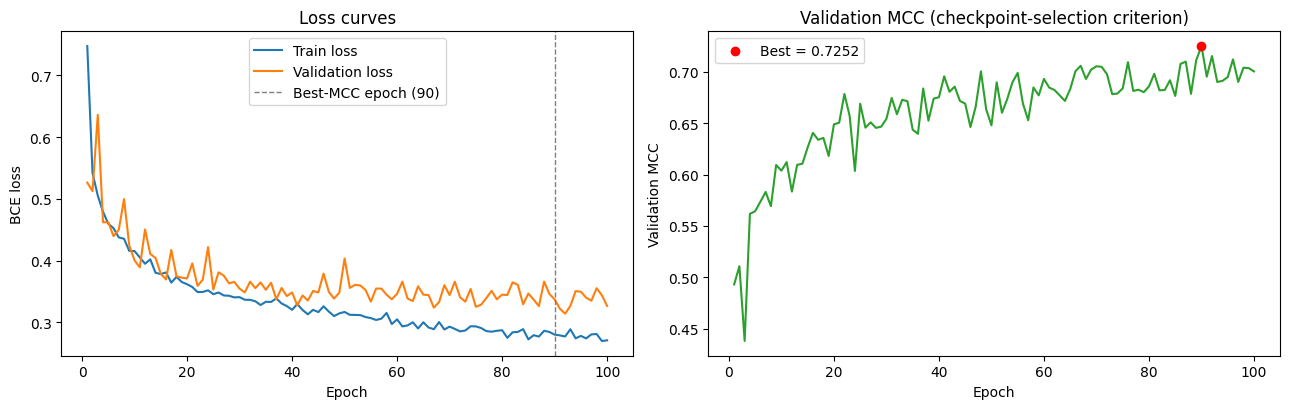

In [15]:
# ---- load the best checkpoint (the same loading logic the original evaluation cell used) ----
def load_graphb3(path):
    m = GraphConvModel(input_features=33, embedding_size=128)
    m.load_state_dict(torch.load(str(path), map_location=device))
    return m.to(device).eval()

@torch.no_grad()
def predict_probs(m, graphs, batch_size=64):
    """P(BBB+) = sigmoid(logit) for each graph, in the order of `graphs`."""
    from torch_geometric.loader import DataLoader as _DL
    m.eval(); out = []
    for b in _DL(graphs, batch_size=batch_size, shuffle=False):
        b = b.to(device); out.extend(torch.sigmoid(m(b.x, b.edge_index, b.batch)).view(-1).cpu().numpy().tolist())
    return np.asarray(out, dtype=float)

graphb3 = load_graphb3(MODEL_PATH)
p_val = predict_probs(graphb3, val_graphs)
print(f"checkpoint {MODEL_PATH} | validation MCC {matthews_corrcoef(yva, (p_val >= THRESHOLD).astype(int)):.4f} | validation AUC {roc_auc_score(yva, p_val):.4f}")
if not TRAIN_GRAPHB3:
    print("NOTE: reused checkpoint - its training provenance cannot be verified from the file itself (see the note above).")

if history is not None:                       # training curves (reused plot) - only available when training ran in this session
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2)); best_ep = history["epoch"][int(np.argmax(history["val_mcc"]))]
    axes[0].plot(history["epoch"], history["train_loss"], label="Train loss"); axes[0].plot(history["epoch"], history["val_loss"], label="Validation loss")
    axes[0].axvline(best_ep, color="gray", linestyle="--", linewidth=1, label=f"Best-MCC epoch ({best_ep})"); axes[0].set(xlabel="Epoch", ylabel="BCE loss", title="Loss curves"); axes[0].legend()
    axes[1].plot(history["epoch"], history["val_mcc"], color="tab:green"); axes[1].scatter([best_ep], [max(history["val_mcc"])], color="red", zorder=3, label=f"Best = {max(history['val_mcc']):.4f}")
    axes[1].set(xlabel="Epoch", ylabel="Validation MCC", title="Validation MCC (checkpoint-selection criterion)"); axes[1].legend(); plt.tight_layout(); plt.show()

#### Optional: how much does GraphB3 move with the random seed? (`RUN_MULTI_SEED`)
Same recipe, but the initial weights, batch order and dropout masks are re-drawn per seed. The **mean ± SD** over seeds, not a single run, is the honest summary of GraphB3's accuracy; this feeds into the limitations in section 16. Seeds are not chosen using the test set. Skipped by default (slow).

In [16]:
def run_one_seed(seed):
    from torch_geometric.loader import DataLoader as _DL
    set_all_seeds(seed)
    m = GraphConvModel(input_features=33, embedding_size=128).to(device)
    torch.manual_seed(seed)                                   # the model class fixes seed 565 inside __init__; re-draw the weights here
    for mod in m.modules():
        if hasattr(mod, "reset_parameters"): mod.reset_parameters()
    opt = torch.optim.Adam(m.parameters(), lr=0.001, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=20)
    crit = torch.nn.BCEWithLogitsLoss(); loader = _DL(train_graphs, batch_size=32, shuffle=True); vloader = _DL(val_graphs, batch_size=32, shuffle=False)
    best, best_state = -9, None
    for ep in range(EPOCHS):
        m.train()
        for b in loader:
            b = b.to(device); opt.zero_grad(); crit(m(b.x, b.edge_index, b.batch).view(-1), b.y.view(-1)).backward(); opt.step()
        m.eval(); lab, pr = [], []
        with torch.no_grad():
            for b in vloader:
                b = b.to(device); pr.extend((m(b.x, b.edge_index, b.batch).view(-1) >= 0).int().cpu().numpy()); lab.extend(b.y.view(-1).int().cpu().numpy())
        v = matthews_corrcoef(lab, pr); sch.step(v)
        if v > best: best, best_state = v, copy.deepcopy(m.state_dict())
    m.load_state_dict(best_state); m.eval(); return m, best

SEED_TABLE = None
if RUN_MULTI_SEED:
    rows = []
    for s in range(N_SEEDS):
        t0 = time.time(); m_s, bv = run_one_seed(s); mt = paper_metrics(y_test, predict_probs(m_s, test_graphs))
        rows.append(dict(seed=s, best_val_MCC=bv, **{k: mt[k] for k in ["Accuracy", "Balanced accuracy", "AUC-ROC", "MCC", "F1"]}))
        print(f"seed {s}: test accuracy {mt['Accuracy']:.4f} | MCC {mt['MCC']:.4f} | AUC {mt['AUC-ROC']:.4f}  [{time.time()-t0:.0f}s]", flush=True)
    SEED_TABLE = pd.DataFrame(rows); display(SEED_TABLE.round(ROUND)); display(SEED_TABLE.drop(columns="seed").agg(["mean", "std"]).round(ROUND))
else:
    print("RUN_MULTI_SEED is False - skipped.")

RUN_MULTI_SEED is False - skipped.


### GraphB3 test-set evaluation
The checkpoint predicts the held-out test molecules once. P(BBB+) is `sigmoid(logit)`; the predicted label is `P(BBB+) ≥ 0.5` (equivalently logit ≥ 0). All probability-based metrics (ROC-AUC, AUC-PR) use this positive-class probability. Precision, recall and F1 refer to the **BBB+** class.

OK: GraphB3 predictions map back to the correct molecule / SMILES (spot-check of 8 rows).
=============== GraphB3 - TEST SET, 1771 molecules, positive class = BBB+, threshold 0.5 ===============


,Accuracy,Balanced accuracy,Precision,Recall,F1,AUC-ROC,AUC-PR,MCC,Specificity
GraphB3,0.8713,0.8523,0.8903,0.915,0.9025,0.9395,0.9624,0.7138,0.7896


Confusion matrix counts: TN=488  FP=130  FN=98  TP=1055
              precision    recall  f1-score   support

    BBB- (0)      0.833     0.790     0.811       618
    BBB+ (1)      0.890     0.915     0.902      1153

    accuracy                          0.871      1771
   macro avg      0.862     0.852     0.857      1771
weighted avg      0.870     0.871     0.870      1771



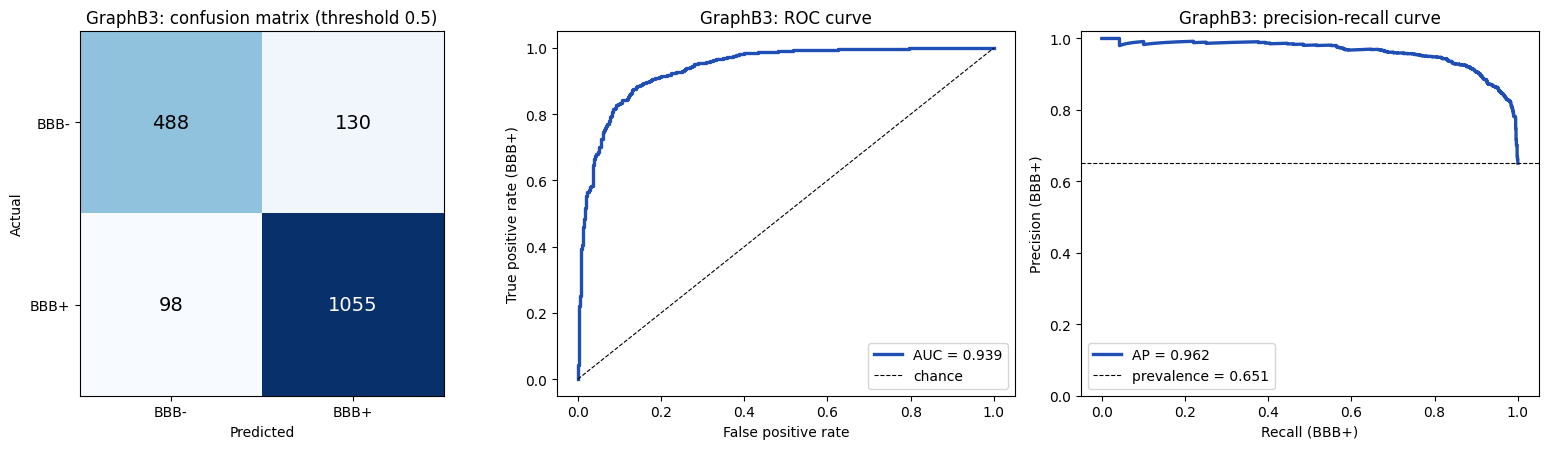

,test_row,mol_id,SMILES,y_true,p_graphb3,pred_graphb3
0,0,60,NCc1c[n+]2ccccc2[nH]1,0,0.7251,1
1,1,61,Nc1ccc(C(=O)O)cc1,0,0.4175,0
2,2,115,O=C(O)c1ccccc1O,0,0.4319,0
3,3,227,Nc1cc(N)c(N)cc1N,1,0.7954,1
4,4,246,CSC(=N)N,1,0.8042,1
5,5,303,NC1(C(=O)O)CCCC1,1,0.2934,0
6,6,311,C=CC#N,1,0.7533,1
7,7,316,NCCCS(=O)(=O)O,1,0.3838,0
8,8,338,CNCCc1ccccn1,1,0.7833,1
9,9,341,ClCCl,1,0.8831,1


In [17]:
P_G = predict_probs(graphb3, test_graphs)
assert len(P_G) == len(te_df) and np.all(np.isfinite(P_G)) and np.all((P_G >= 0) & (P_G <= 1)), "invalid GraphB3 test probabilities"
PROBS_TEST["GraphB3"] = P_G
PRED_DF["p_graphb3"] = P_G; PRED_DF["pred_graphb3"] = (P_G >= THRESHOLD).astype(int)

# ---- verify that predictions map back to the right molecule: re-featurise 8 random test SMILES from scratch ----
rng_chk = np.random.default_rng(SEED)
for i in rng_chk.choice(len(te_df), size=min(8, len(te_df)), replace=False):
    g = smiles_to_graph(PRED_DF.loc[i, "SMILES"]); d = Data(x=g[0], edge_index=g[1])
    p_re = predict_probs(graphb3, [d])[0]
    assert abs(p_re - PRED_DF.loc[i, "p_graphb3"]) < 1e-4, f"prediction for test row {i} does not map back to its SMILES"
print("OK: GraphB3 predictions map back to the correct molecule / SMILES (spot-check of 8 rows).")

RESULTS["GraphB3"] = report_model("GraphB3", y_test, P_G, "#1f4eb4")
display(PRED_DF[["test_row", "mol_id", "SMILES", "y_true", "p_graphb3", "pred_graphb3"]].head(10).round(4))

## 9. Extra Trees: training, tuning and evaluation

### Preprocessing pipeline (reused code, unchanged)
Every step is **fitted on training data only** and is re-fitted inside each cross-validation fold, so nothing leaks from validation or test data:
median imputation → **clip each descriptor to the training min/max** → drop constant columns → drop descriptors with |r| > 0.95 to an earlier kept descriptor → standard scaling → model. (Scaling is harmless for trees; it is kept so the pipeline is identical to the original.) Because the pipeline works on arrays, descriptor **names are tracked explicitly** (`kept_features`) and used for every importance value in section 14.

### Model and tuning (original configuration)
`ExtraTreesClassifier(n_estimators=300)` — the target is binary, so the classifier is the appropriate variant. Hyperparameters (`max_depth`, `min_samples_leaf`, `max_features`) are tuned with **randomised search** (`N_ITER` draws, seed `RANDOM_STATE`) using **stratified k-fold CV on the training split only**, scored by **MCC** (AUC recorded as a tie-breaker diagnostic). The best setting is refit on the whole training split. The validation split is then used as an additional check. **The test set plays no role in tuning.**

In [18]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, ParameterGrid
from sklearn.metrics import make_scorer

class TrainRangeClipper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): X = np.asarray(X, float); self.lo_, self.hi_ = np.nanmin(X, 0), np.nanmax(X, 0); return self
    def transform(self, X): return np.clip(np.asarray(X, float), self.lo_, self.hi_)
class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.95): self.threshold = threshold
    def fit(self, X, y=None):
        C = np.nan_to_num(np.abs(np.corrcoef(np.asarray(X, float), rowvar=False))); keep = []
        for j in range(C.shape[0]):
            if all(C[j, k] <= self.threshold for k in keep): keep.append(j)
        self.keep_ = np.array(keep); return self
    def transform(self, X): return np.asarray(X)[:, self.keep_]

def make_pipe(est):
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("clip", TrainRangeClipper()), ("var", VarianceThreshold(1e-8)),
                     ("corr", CorrelationFilter(0.95)), ("scale", StandardScaler()), ("model", est)])
def kept_features(pipe):
    names = np.array(NAMES)[pipe.named_steps["var"].get_support()]; return list(names[pipe.named_steps["corr"].keep_])

In [19]:
# ---- the single retained model + its search space (both taken from the original model zoo) ----
ET_ESTIMATOR = ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)
ET_GRID = {"model__max_depth": [None, 12, 20], "model__min_samples_leaf": [1, 2, 4], "model__max_features": ["sqrt", 0.5]}
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=42); mcc_scorer = make_scorer(matthews_corrcoef)

t0 = time.time()
search = RandomizedSearchCV(make_pipe(ET_ESTIMATOR), ET_GRID, n_iter=min(N_ITER, len(ParameterGrid(ET_GRID))),
                            scoring={"mcc": mcc_scorer, "auc": "roc_auc"}, refit="mcc", cv=cv, n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, ytr)
et_model = search.best_estimator_                      # a fitted Pipeline (preprocessing + ExtraTreesClassifier), trained on the training split only
cvr = pd.DataFrame(search.cv_results_)
tuning_tab = pd.DataFrame({"max_depth": cvr["param_model__max_depth"], "min_samples_leaf": cvr["param_model__min_samples_leaf"], "max_features": cvr["param_model__max_features"],
                           "CV MCC": cvr["mean_test_mcc"], "CV MCC sd": cvr["std_test_mcc"], "CV AUC": cvr["mean_test_auc"]}).sort_values("CV MCC", ascending=False)
print(f"randomised search: {len(tuning_tab)} configurations x {CV_FOLDS}-fold CV on {len(Xtr)} TRAINING molecules  [{time.time()-t0:.0f}s]")
display(tuning_tab.round(ROUND).reset_index(drop=True))
ET_BEST_PARAMS = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("SELECTED hyperparameters:", ET_BEST_PARAMS)

# ---- explicit class handling: P(BBB+) must come from the column of class 1 ----
et_clf = et_model.named_steps["model"]; POS_COL = list(et_clf.classes_).index(1)
def et_proba(X): return et_model.predict_proba(X)[:, POS_COL]
p_val_et = et_proba(Xva)
print(f"validation check (not used for tuning): MCC {matthews_corrcoef(yva, (p_val_et >= THRESHOLD).astype(int)):.4f} | AUC {roc_auc_score(yva, p_val_et):.4f}")

randomised search: 8 configurations x 5-fold CV on 4821 TRAINING molecules  [44s]


,max_depth,min_samples_leaf,max_features,CV MCC,CV MCC sd,CV AUC
0,None,2,0.5,0.7444,0.0100,0.9502
1,None,2,sqrt,0.7416,0.0073,0.9508
2,20,2,0.5,0.7415,0.0092,0.9500
3,12,2,0.5,0.7249,0.0145,0.9447
4,None,4,sqrt,0.7196,0.0128,0.9438
5,20,4,sqrt,0.7168,0.0183,0.9437
6,12,1,sqrt,0.7102,0.0173,0.9426
7,12,4,sqrt,0.6922,0.0177,0.9345


SELECTED hyperparameters: {'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': None}
validation check (not used for tuning): MCC 0.7448 | AUC 0.9553


In [20]:
# ---- final model configuration and the descriptors it actually uses (names kept with values) ----
ET_KEPT = [str(n) for n in kept_features(et_model)]
var_mask = et_model.named_steps["var"].get_support(); ET_CONST_DROPPED = [n for n, k in zip(NAMES, var_mask) if not k]
Xt = et_model[:3].transform(Xtr); C = np.nan_to_num(np.abs(np.corrcoef(Xt, rowvar=False)))          # after impute / clip / variance filter
names_after_var = [n for n, k in zip(NAMES, var_mask) if k]; kept_pos = list(et_model.named_steps["corr"].keep_)
ET_CORR_DROPPED = {}
for j, n in enumerate(names_after_var):
    if j not in kept_pos:
        k = next(k for k in kept_pos if C[j, k] > et_model.named_steps["corr"].threshold); ET_CORR_DROPPED[n] = names_after_var[k]
assert len(ET_KEPT) == et_clf.n_features_in_ == len(et_clf.feature_importances_) and len(ET_KEPT) + len(ET_CONST_DROPPED) + len(ET_CORR_DROPPED) == len(NAMES)
print("FINAL Extra Trees model")
print("  preprocessing :", " -> ".join(s for s, _ in et_model.steps[:-1]), "(all fitted on the training split)")
print("  estimator     :", {k: v for k, v in et_clf.get_params().items() if k in ("n_estimators", "max_depth", "min_samples_leaf", "max_features", "criterion", "bootstrap", "class_weight", "random_state")})
print(f"  descriptors   : {len(NAMES)} computed -> {len(ET_KEPT)} used by the model")
print("  dropped (constant in training data):", ET_CONST_DROPPED or "none")
print("  dropped (|r| > 0.95 with an earlier kept descriptor):", ET_CORR_DROPPED or "none")
print("  used:", ET_KEPT)

FINAL Extra Trees model
  preprocessing : imp -> clip -> var -> corr -> scale (all fitted on the training split)
  estimator     : {'bootstrap': False, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 300, 'random_state': 0}
  descriptors   : 34 computed -> 27 used by the model
  dropped (constant in training data): none
  dropped (|r| > 0.95 with an earlier kept descriptor): {'HeavyAtomCount': 'MolWt', 'LabuteASA': 'MolWt', 'MolMR': 'MolWt', 'NumValenceElectrons': 'MolWt', 'Kappa1': 'MolWt', 'Chi0v': 'MolWt', 'Chi1v': 'MolWt'}
  used: ['MolWt', 'MolLogP', 'TPSA', 'NumHDonors', 'NumHAcceptors', 'NumHeteroatoms', 'NumRotatableBonds', 'FractionCSP3', 'Kappa2', 'Kappa3', 'RingCount', 'NumAromaticRings', 'NumAliphaticRings', 'NumSaturatedRings', 'BertzCT', 'BalabanJ', 'HallKierAlpha', 'FormalCharge', 'NumPositiveAtoms', 'NumNegativeAtoms', 'nN', 'nO', 'nS', 'nHalogen', 'nCarboxylicAcid', 'nBasicAmine', 'nQuaternaryN']

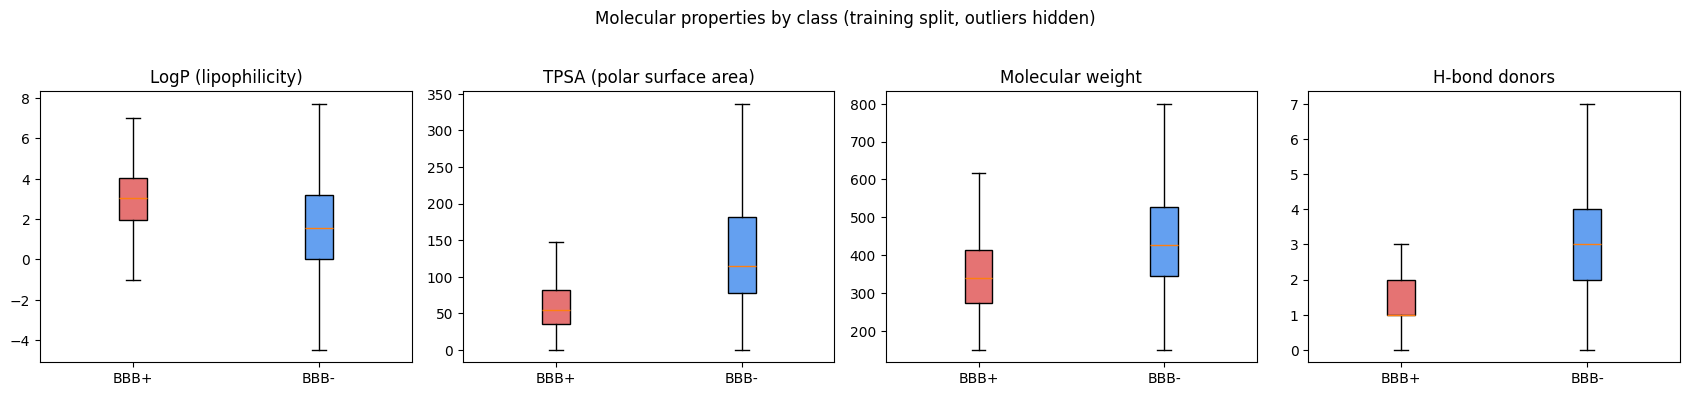

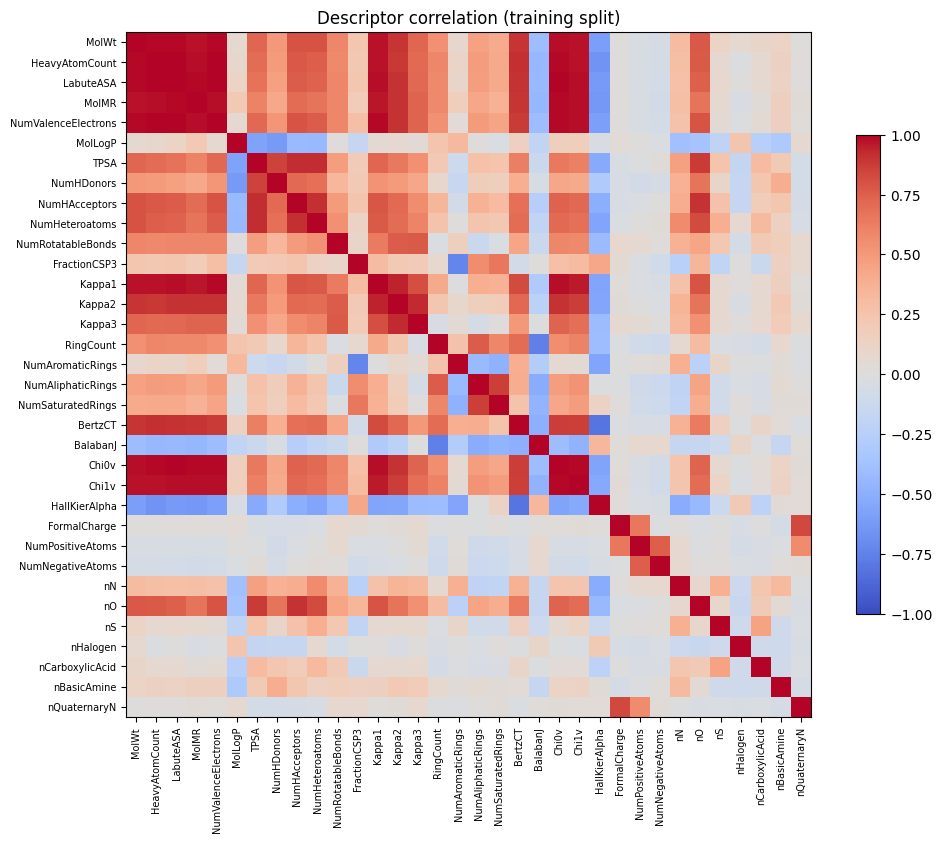

In [21]:
# ---- optional look at the data (reused idea): class differences of four key descriptors, and descriptor correlations (training split) ----
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, c, t_ in zip(ax, ["MolLogP", "TPSA", "MolWt", "NumHDonors"], ["LogP (lipophilicity)", "TPSA (polar surface area)", "Molecular weight", "H-bond donors"]):
    bp = a.boxplot([Xtr[c][ytr == 1], Xtr[c][ytr == 0]], labels=["BBB+", "BBB-"], showfliers=False, patch_artist=True)
    for patch, col in zip(bp["boxes"], ["#e57373", "#64a0f0"]): patch.set_facecolor(col)
    a.set_title(t_)
plt.suptitle("Molecular properties by class (training split, outliers hidden)", y=1.03); plt.tight_layout(); plt.show()
plt.figure(figsize=(10.5, 8.5)); cm_ = Xtr.corr().values; plt.imshow(cm_, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar(shrink=.7)
plt.xticks(range(len(NAMES)), NAMES, rotation=90, fontsize=7); plt.yticks(range(len(NAMES)), NAMES, fontsize=7); plt.title("Descriptor correlation (training split)"); plt.tight_layout(); plt.show()

### Extra Trees test-set evaluation
Evaluated on **exactly the same test molecules, in the same order** as GraphB3 (descriptor row *i* ↔ test graph *i* ↔ `te_df` row *i*), with the same metric function, threshold and plot types.

OK: Extra Trees predictions map back to the correct molecule / SMILES (spot-check of 8 rows).
=============== Extra Trees - TEST SET, 1771 molecules, positive class = BBB+, threshold 0.5 ===============


,Accuracy,Balanced accuracy,Precision,Recall,F1,AUC-ROC,AUC-PR,MCC,Specificity
Extra Trees,0.8882,0.8661,0.8943,0.9393,0.9162,0.9485,0.9694,0.7505,0.7929


Confusion matrix counts: TN=490  FP=128  FN=70  TP=1083
              precision    recall  f1-score   support

    BBB- (0)      0.875     0.793     0.832       618
    BBB+ (1)      0.894     0.939     0.916      1153

    accuracy                          0.888      1771
   macro avg      0.885     0.866     0.874      1771
weighted avg      0.888     0.888     0.887      1771



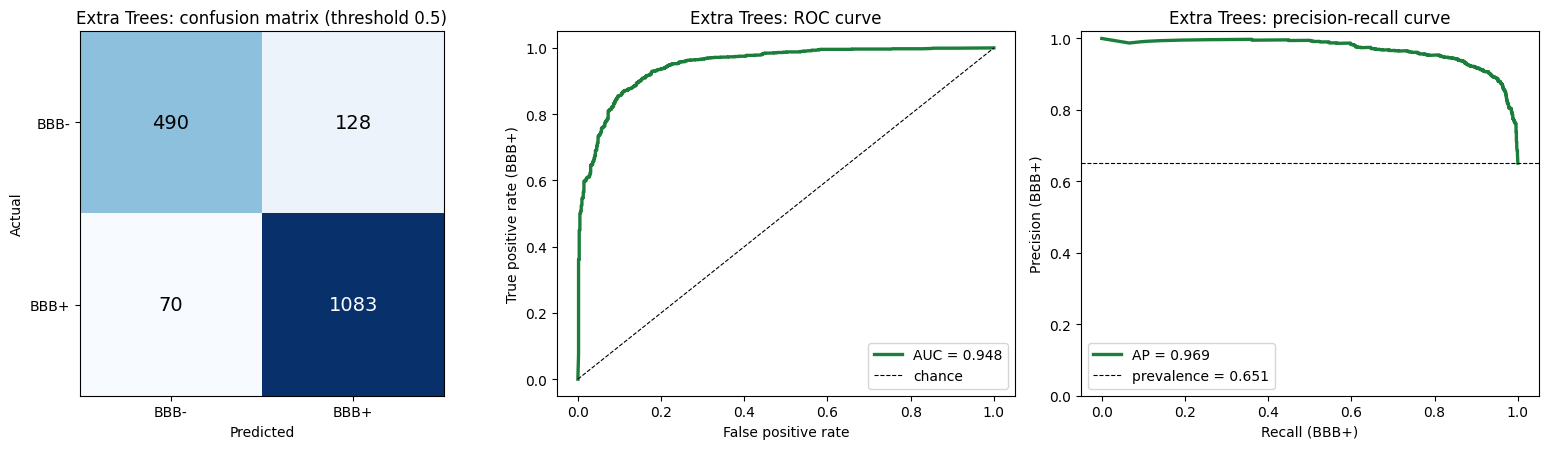

,test_row,mol_id,SMILES,y_true,p_extratrees,pred_extratrees
0,0,60,NCc1c[n+]2ccccc2[nH]1,0,0.5228,1
1,1,61,Nc1ccc(C(=O)O)cc1,0,0.5362,1
2,2,115,O=C(O)c1ccccc1O,0,0.5871,1
3,3,227,Nc1cc(N)c(N)cc1N,1,0.2574,0
4,4,246,CSC(=N)N,1,0.6082,1
5,5,303,NC1(C(=O)O)CCCC1,1,0.5604,1
6,6,311,C=CC#N,1,0.7312,1
7,7,316,NCCCS(=O)(=O)O,1,0.4884,0
8,8,338,CNCCc1ccccn1,1,0.8125,1
9,9,341,ClCCl,1,0.8331,1


In [22]:
assert list(X_te.columns) == NAMES and len(X_te) == len(te_df) == len(P_G) and (te_df["SMILES"].values == PRED_DF["SMILES"].values).all()
P_ET = et_proba(X_te)
assert np.all(np.isfinite(P_ET)) and np.all((P_ET >= 0) & (P_ET <= 1)), "invalid Extra Trees test probabilities"
PROBS_TEST["Extra Trees"] = P_ET
PRED_DF["p_extratrees"] = P_ET; PRED_DF["pred_extratrees"] = (P_ET >= THRESHOLD).astype(int)

# ---- verify that predictions map back to the molecule: recompute descriptors from the SMILES of 8 random test rows ----
for i in np.random.default_rng(SEED).choice(len(te_df), size=min(8, len(te_df)), replace=False):
    row, _ = compute_descriptors([PRED_DF.loc[i, "SMILES"]])
    assert abs(et_proba(row)[0] - PRED_DF.loc[i, "p_extratrees"]) < 1e-9, f"Extra Trees prediction for test row {i} does not map back to its SMILES"
print("OK: Extra Trees predictions map back to the correct molecule / SMILES (spot-check of 8 rows).")

RESULTS["Extra Trees"] = report_model("Extra Trees", y_test, P_ET, "#1b7f3b")
display(PRED_DF[["test_row", "mol_id", "SMILES", "y_true", "p_extratrees", "pred_extratrees"]].head(10).round(4))

## 10. Side-by-side model comparison
One table, same metrics, same rounding, same 0.5 threshold, same test molecules. The comparison below is limited to **GraphB3 and Extra Trees**. The statistical checks (retained from the original notebook) are:
* **Exact McNemar test** on the molecules where exactly one model is right — does one model win those disagreements more often than chance?
* **Paired bootstrap** (resampling the *test molecules*) of the difference in AUC-ROC, MCC and accuracy. An interval that contains 0 means the test set alone cannot separate the models on that metric. This reflects *test-set sampling noise only*; it does not capture training randomness (GraphB3 seed spread, tuning noise) or a different train/test split.

In [23]:
NAMES2 = ["GraphB3", "Extra Trees"]
cmp_tab = pd.DataFrame({n: {k: RESULTS[n][k] for k in METRIC_COLS + ["Specificity"]} for n in NAMES2}).T
cmp_tab.loc["difference (GraphB3 - Extra Trees)"] = cmp_tab.loc["GraphB3"] - cmp_tab.loc["Extra Trees"]
print(f"===== TEST SET: {len(y_test)} molecules ({int(y_test.sum())} BBB+ / {int((y_test==0).sum())} BBB-), threshold {THRESHOLD}, positive class BBB+ =====")
display(cmp_tab.round(ROUND))
if SEED_TABLE is not None:
    print("GraphB3 multi-seed spread (optional run):"); display(SEED_TABLE.drop(columns="seed").agg(["mean", "std"]).round(ROUND))

===== TEST SET: 1771 molecules (1153 BBB+ / 618 BBB-), threshold 0.5, positive class BBB+ =====


,Accuracy,Balanced accuracy,Precision,Recall,F1,AUC-ROC,AUC-PR,MCC,Specificity
GraphB3,0.8713,0.8523,0.8903,0.9150,0.9025,0.9395,0.9624,0.7138,0.7896
Extra Trees,0.8882,0.8661,0.8943,0.9393,0.9162,0.9485,0.9694,0.7505,0.7929
difference (GraphB3 - Extra Trees),-0.0169,-0.0138,-0.0040,-0.0243,-0.0138,-0.0090,-0.0070,-0.0367,-0.0032


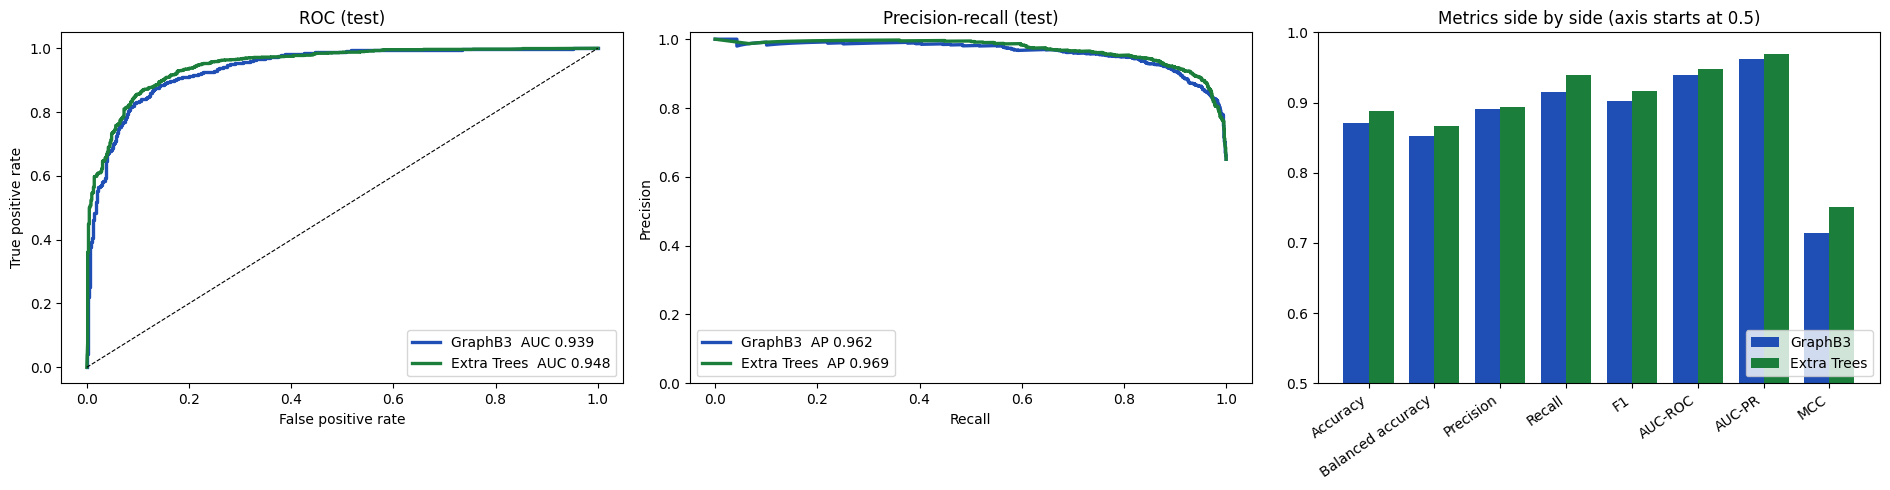

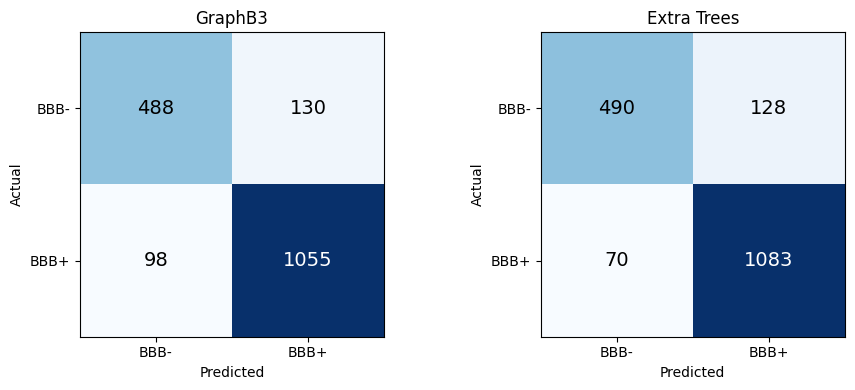

In [24]:
COL = {"GraphB3": "#1f4eb4", "Extra Trees": "#1b7f3b"}
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for n in NAMES2:
    f, t_, _ = roc_curve(y_test, PROBS_TEST[n]); ax[0].plot(f, t_, color=COL[n], lw=2.4, label=f"{n}  AUC {RESULTS[n]['AUC-ROC']:.3f}")
    p_, r_, _ = precision_recall_curve(y_test, PROBS_TEST[n]); ax[1].plot(r_, p_, color=COL[n], lw=2.4, label=f"{n}  AP {RESULTS[n]['AUC-PR']:.3f}")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (test)"); ax[0].legend(loc="lower right")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall (test)", ylim=(0, 1.02)); ax[1].legend(loc="lower left")
x = np.arange(len(METRIC_COLS)); w = 0.38
for k, n in enumerate(NAMES2): ax[2].bar(x + (k - .5) * w, [RESULTS[n][m] for m in METRIC_COLS], w, label=n, color=COL[n])
ax[2].set_xticks(x); ax[2].set_xticklabels(METRIC_COLS, rotation=35, ha="right"); ax[2].set_ylim(0.5, 1.0); ax[2].legend(loc="lower right"); ax[2].set_title("Metrics side by side (axis starts at 0.5)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9.5, 4))
for a, n in zip(ax, NAMES2):
    r = RESULTS[n]; cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]]); a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, str(v), ha="center", va="center", fontsize=14, color="white" if v > cm.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["BBB-", "BBB+"]); a.set_yticks([0, 1]); a.set_yticklabels(["BBB-", "BBB+"]); a.set(title=n, xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); plt.show()

In [25]:
from scipy.stats import binomtest
yg, ye = PRED_DF["pred_graphb3"].values, PRED_DF["pred_extratrees"].values; cg, ce = yg == y_test, ye == y_test
grp = pd.Series({"both correct": int((cg & ce).sum()), "both wrong": int((~cg & ~ce).sum()), "only GraphB3 correct": int((cg & ~ce).sum()), "only Extra Trees correct": int((~cg & ce).sum())})
display(grp.to_frame("molecules"))
print(f"the two models give the same label for {(yg == ye).mean()*100:.1f}% of the test molecules; accuracy on those: {cg[yg == ye].mean()*100:.1f}%")
b, c = int((cg & ~ce).sum()), int((~cg & ce).sum())
MCNEMAR_P = binomtest(b, b + c, 0.5).pvalue if (b + c) > 0 else 1.0
print(f"exact McNemar test: GraphB3-only-right = {b}, Extra-Trees-only-right = {c}, two-sided p = {MCNEMAR_P:.4g}")

def paired_bootstrap(y, pa, pb, n_boot, seed):
    rng = np.random.default_rng(seed); n = len(y); d = {"AUC-ROC": [], "MCC": [], "Accuracy": []}; ha, hb = (pa >= THRESHOLD).astype(int), (pb >= THRESHOLD).astype(int)
    for _ in range(n_boot):
        i = rng.integers(0, n, n); yi = y[i]
        if yi.min() == yi.max(): continue
        d["AUC-ROC"].append(roc_auc_score(yi, pa[i]) - roc_auc_score(yi, pb[i])); d["MCC"].append(matthews_corrcoef(yi, ha[i]) - matthews_corrcoef(yi, hb[i]))
        d["Accuracy"].append((ha[i] == yi).mean() - (hb[i] == yi).mean())
    return {k: (float(np.mean(v)), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)), len(v)) for k, v in d.items()}
BOOT = paired_bootstrap(y_test, P_G, P_ET, N_BOOT, SEED)
boot_tab = pd.DataFrame({k: {"observed diff (GraphB3 - ET)": RESULTS["GraphB3"][k] - RESULTS["Extra Trees"][k], "bootstrap mean": v[0], "95% CI low": v[1], "95% CI high": v[2],
                             "CI excludes 0": not (v[1] <= 0 <= v[2]), "valid resamples": v[3]} for k, v in BOOT.items()}).T
print(f"\npaired bootstrap over test molecules ({N_BOOT} resamples, seed {SEED}):"); display(boot_tab.round(ROUND))

if "mol_wt" in te_df.columns:        # retained from the original: the test set contains molecules outside the training mass range
    mw = te_df["mol_wt"].values; lo, hi = float(Xtr["MolWt"].min()), float(Xtr["MolWt"].max())
    sub = np.where(mw < lo, f"MW < {lo:.0f} (below training range)", np.where(mw > hi, f"MW > {hi:.0f} (above training range)", "inside training range"))
    print("\naccuracy by molecular-weight range (descriptive only; small subgroups are noisy):")
    display(pd.DataFrame({"n": pd.Series(sub).value_counts(), "GraphB3": pd.Series(cg).groupby(sub).mean(), "Extra Trees": pd.Series(ce).groupby(sub).mean()}).round(ROUND))

if TEST_OVERLAP_MASK.any():          # sensitivity check for train/test duplicates (section 4)
    keep = ~TEST_OVERLAP_MASK; print(f"\nSENSITIVITY: {int(TEST_OVERLAP_MASK.sum())} test molecules also occur in the training data. Metrics on the remaining {int(keep.sum())} test molecules:")
    display(pd.DataFrame({n: {k: paper_metrics(y_test[keep], PROBS_TEST[n][keep])[k] for k in ["Accuracy", "AUC-ROC", "MCC"]} for n in NAMES2}).T.round(ROUND))
else:
    print("\nNo train/test duplicates detected -> no overlap sensitivity analysis needed.")

,molecules
both correct,1469
both wrong,124
only GraphB3 correct,74
only Extra Trees correct,104


the two models give the same label for 89.9% of the test molecules; accuracy on those: 92.2%
exact McNemar test: GraphB3-only-right = 74, Extra-Trees-only-right = 104, two-sided p = 0.02945

paired bootstrap over test molecules (1000 resamples, seed 0):


,observed diff (GraphB3 - ET),bootstrap mean,95% CI low,95% CI high,CI excludes 0,valid resamples
AUC-ROC,-0.008966,-0.008904,-0.018962,0.000555,False,1000
MCC,-0.036711,-0.036567,-0.068205,-0.004354,True,1000
Accuracy,-0.01694,-0.016865,-0.03107,-0.002809,True,1000



accuracy by molecular-weight range (descriptive only; small subgroups are noisy):


,n,GraphB3,Extra Trees
MW < 150 (below training range),235,0.8638,0.8553
MW > 1203 (above training range),30,1.0000,1.0000
inside training range,1506,0.8699,0.8911



No train/test duplicates detected -> no overlap sensitivity analysis needed.


### Interpretation (the text below is generated from the numbers above — nothing is typed in by hand)

In [26]:
g, e = RESULTS["GraphB3"], RESULTS["Extra Trees"]
diffs = {k: g[k] - e[k] for k in METRIC_COLS}
print("MEASURED differences on the held-out test set (GraphB3 - Extra Trees):")
for k, d in diffs.items(): print(f"  {k:<18} {g[k]:.4f} vs {e[k]:.4f}   -> {'GraphB3' if d > 0 else 'Extra Trees' if d < 0 else 'tie'} higher by {abs(d):.4f}")
nG = sum(d > 0 for d in diffs.values()); nE = sum(d < 0 for d in diffs.values())
print(f"\nGraphB3 is higher on {nG} of {len(METRIC_COLS)} metrics, Extra Trees on {nE}.")
se = np.sqrt(g["Accuracy"] * (1 - g["Accuracy"]) / len(y_test)); print(f"One accuracy estimated on {len(y_test)} molecules has a binomial standard error of about {se*100:.2f} percentage points, and one molecule = {100/len(y_test):.3f} points.")
print(f"Different errors? Yes if the 'only ... correct' counts are non-zero: GraphB3-only-right {b}, Extra-Trees-only-right {c}, both wrong {int((~cg & ~ce).sum())}.")

print("\nSTATISTICAL assessment (single split; three tests, no multiple-comparison correction):")
print(f"  McNemar exact p = {MCNEMAR_P:.4g}  ({'<' if MCNEMAR_P < 0.05 else '>='} 0.05)")
dirs = []
for k in ["AUC-ROC", "MCC", "Accuracy"]:
    m_, lo_, hi_, _ = BOOT[k]; excl = not (lo_ <= 0 <= hi_); dirs.append((k, excl, np.sign(m_)))
    print(f"  bootstrap {k:<8}: 95% CI [{lo_:+.4f}, {hi_:+.4f}] -> {'excludes 0' if excl else 'contains 0'}")
all_excl = all(x[1] for x in dirs) and MCNEMAR_P < 0.05 and len({x[2] for x in dirs}) == 1
if all_excl: print(f"\n=> All three checks point the same way: on THIS test set the {'GraphB3' if dirs[0][2] > 0 else 'Extra Trees'} advantage is unlikely to be test-sampling noise alone.")
else:         print("\n=> The checks do not all separate the models (see which intervals contain 0 / the McNemar p-value). Treat the measured differences as NOT established; do not name a winner on these data.")
print("Caveats: (1) this is ONE train/validation/test split; (2) the bootstrap covers test-set sampling only, not training randomness"
      + (" (see the multi-seed table above)." if SEED_TABLE is not None else " (run RUN_MULTI_SEED to measure GraphB3's seed spread).")
      + " (3) a statistically detectable difference can still be small in practical terms - judge the size of the differences above.")

MEASURED differences on the held-out test set (GraphB3 - Extra Trees):
  Accuracy           0.8713 vs 0.8882   -> Extra Trees higher by 0.0169
  Balanced accuracy  0.8523 vs 0.8661   -> Extra Trees higher by 0.0138
  Precision          0.8903 vs 0.8943   -> Extra Trees higher by 0.0040
  Recall             0.9150 vs 0.9393   -> Extra Trees higher by 0.0243
  F1                 0.9025 vs 0.9162   -> Extra Trees higher by 0.0138
  AUC-ROC            0.9395 vs 0.9485   -> Extra Trees higher by 0.0090
  AUC-PR             0.9624 vs 0.9694   -> Extra Trees higher by 0.0070
  MCC                0.7138 vs 0.7505   -> Extra Trees higher by 0.0367

GraphB3 is higher on 0 of 8 metrics, Extra Trees on 8.
One accuracy estimated on 1771 molecules has a binomial standard error of about 0.80 percentage points, and one molecule = 0.056 points.
Different errors? Yes if the 'only ... correct' counts are non-zero: GraphB3-only-right 74, Extra-Trees-only-right 104, both wrong 124.

STATISTICAL assessment 

## 10b. Molecule-by-molecule comparison table and CSV export (checklist item 5)
One row per held-out test molecule: ID, SMILES, actual label, each model's predicted label / probability / correctness, and one of four categories. Before the table is built, the cell **re-verifies the alignment** (test-row index, molecule ID, SMILES and label must equal the test workbook rows, in order) — it does not rely on the arrays merely having the same length. Predicted labels use the single `THRESHOLD` for both models. In a two-class problem the models disagree on a molecule **exactly when one of them is wrong**, so categories 2 + 3 are precisely the disagreement cases. Saved to `bbb_outputs/molecule_comparison.csv` (plus `metrics_comparison.csv`).

In [27]:
# ---- alignment check against the test workbook rows (not just equal length) ----
need = ["test_row", "mol_id", "SMILES", "y_true", "p_graphb3", "pred_graphb3", "p_extratrees", "pred_extratrees"]
assert all(c in PRED_DF.columns for c in need), f"PRED_DF is missing {set(need) - set(PRED_DF.columns)}"
assert len(PRED_DF) == len(te_df) == len(y_test) and (PRED_DF["test_row"].values == np.arange(len(te_df))).all()
for col_pred, col_te in (("mol_id", "mol_id"), ("SMILES", "SMILES")):
    bad = np.where(PRED_DF[col_pred].astype(str).values != te_df[col_te].astype(str).values)[0]
    assert len(bad) == 0, f"{col_pred} differs from the test workbook at rows {bad[:5].tolist()}"
assert (PRED_DF["y_true"].values == y_test).all(), "labels differ from the test labels"
print(f"OK: both models' predictions line up with the {len(te_df)} test-workbook rows (IDs, SMILES, labels, order).")

CMP = PRED_DF[need].rename(columns={"y_true": "actual_label", "p_graphb3": "graphb3_prob", "pred_graphb3": "graphb3_pred_label",
                                    "p_extratrees": "extratrees_prob", "pred_extratrees": "extratrees_pred_label"}).copy()
CMP["graphb3_correct"] = CMP.graphb3_pred_label == CMP.actual_label; CMP["extratrees_correct"] = CMP.extratrees_pred_label == CMP.actual_label
CAT_BOTH_OK = "1. Both models correct"
CAT_G_WRONG = "2. GraphB3 wrong, molecular model (Extra Trees) correct"
CAT_E_WRONG = "3. GraphB3 correct, molecular model (Extra Trees) wrong"
CAT_BOTH_WRONG = "4. Both models wrong"
_cat = {(True, True): CAT_BOTH_OK, (False, True): CAT_G_WRONG, (True, False): CAT_E_WRONG, (False, False): CAT_BOTH_WRONG}
CMP["category"] = [_cat[(a, b)] for a, b in zip(CMP.graphb3_correct, CMP.extratrees_correct)]
CMP["models_agree"] = CMP.graphb3_pred_label == CMP.extratrees_pred_label
CMP = CMP[["test_row", "mol_id", "SMILES", "actual_label", "graphb3_pred_label", "graphb3_prob", "graphb3_correct",
           "extratrees_pred_label", "extratrees_prob", "extratrees_correct", "models_agree", "category"]]
CMP.to_csv(OUT_DIR / "molecule_comparison.csv", index=False)
pd.DataFrame({m: {k: RESULTS[m][k] for k in METRIC_COLS} for m in ("GraphB3", "Extra Trees")}).T.to_csv(OUT_DIR / "metrics_comparison.csv")
print(f"saved {len(CMP)} rows -> {OUT_DIR/'molecule_comparison.csv'}\n"); print(CMP.category.value_counts().sort_index().to_string())
print(f"\nthe models give different labels on {int((~CMP.models_agree).sum())} molecules (= categories 2 + 3: exactly one of them is wrong)")
display(CMP.head(8).round(4))

OK: both models' predictions line up with the 1771 test-workbook rows (IDs, SMILES, labels, order).
saved 1771 rows -> bbb_outputs/molecule_comparison.csv

category
1. Both models correct                                     1469
2. GraphB3 wrong, molecular model (Extra Trees) correct     104
3. GraphB3 correct, molecular model (Extra Trees) wrong      74
4. Both models wrong                                        124

the models give different labels on 178 molecules (= categories 2 + 3: exactly one of them is wrong)


,test_row,mol_id,SMILES,actual_label,graphb3_pred_label,graphb3_prob,graphb3_correct,extratrees_pred_label,extratrees_prob,extratrees_correct,models_agree,category
0,0,60,NCc1c[n+]2ccccc2[nH]1,0,1,0.7251,False,1,0.5228,False,True,4. Both models wrong
1,1,61,Nc1ccc(C(=O)O)cc1,0,0,0.4175,True,1,0.5362,False,False,"3. GraphB3 correct, molecular model (Extra Tre..."
2,2,115,O=C(O)c1ccccc1O,0,0,0.4319,True,1,0.5871,False,False,"3. GraphB3 correct, molecular model (Extra Tre..."
3,3,227,Nc1cc(N)c(N)cc1N,1,1,0.7954,True,0,0.2574,False,False,"3. GraphB3 correct, molecular model (Extra Tre..."
4,4,246,CSC(=N)N,1,1,0.8042,True,1,0.6082,True,True,1. Both models correct
5,5,303,NC1(C(=O)O)CCCC1,1,0,0.2934,False,1,0.5604,True,False,"2. GraphB3 wrong, molecular model (Extra Trees..."
6,6,311,C=CC#N,1,1,0.7533,True,1,0.7312,True,True,1. Both models correct
7,7,316,NCCCS(=O)(=O)O,1,0,0.3838,False,0,0.4884,False,True,4. Both models wrong


## 11. GraphB3 explainability: atom-level importance

### Method
The original **GNNExplainer** configuration is kept: `Explainer(GNNExplainer(epochs=2000), explanation_type="model", node_mask_type="attributes", edge_mask_type="object", mode="binary_classification", return_type="raw")`. For one molecule it learns, by gradient descent, a soft mask that tries to keep the model's output while being sparse:
* a **node-feature mask** of shape *(atoms × 33)* — one value in [0, 1] per atom *per feature* (`node_mask_type="attributes"`);
* an **edge mask** of shape *(directed edges)* — one value in [0, 1] per directed edge (section 12).

**Which class is explained.** With `explanation_type="model"` the target is the class the model **predicted** (BBB+ if P(BBB+) ≥ 0.5, else BBB−), *not* the experimental label. A high score therefore means "the explainer needed this to keep the model's *own* prediction", for BBB− predictions as well as BBB+ ones. Every viewer, table and figure states the explained class.

### From 33 feature scores to one score per atom
A feature-level mask is **not** automatically one number per atom, so the aggregation is made explicit:

* Most of the 33 features are one-hot. A feature whose input value is 0 cannot influence the model, so the explainer assigns it no gradient and PyG sets its mask to exactly 0. Averaging over *all* 33 features would therefore mostly measure how many features happen to be switched on for that atom type.
* **Default `ATOM_AGG = "mean_active"`:** *atom score = mean of the mask values over that atom's **active** (non-zero input) features.* It reads as "the average fraction of the atom's input information the explainer chose to retain", is bounded by [0, 1], and does not favour atoms that simply have more active features. `ATOM_AGG = "sum"` (total retained mask mass) is available as an alternative.
* Scores belong to the atom's **input features**; message passing means neighbours also influence the prediction, which the edge mask captures separately.

### Validity checks and normalisation
Non-finite masks, wrong shapes, or an identically-zero mask are reported as *unavailable* — no artificial scores are generated. An individual atom with score 0 is a legitimate value. For colouring only, scores are **min–max normalised within the molecule** (lowest atom → 0, highest → 1); if all atoms have identical scores no colour scale is applied (grey) because there is nothing to distinguish. Normalised values are *relative within one molecule*: they are **not probabilities**, not calibrated, and not comparable across molecules. Raw scores are always shown next to them.

In [28]:
from torch_geometric.data import Batch
from torch_geometric.explain import Explainer, GNNExplainer

def build_explainer(model, epochs):
    """SAME configuration as the original notebook."""
    return Explainer(model=model, algorithm=GNNExplainer(epochs=epochs), explanation_type="model", node_mask_type="attributes", edge_mask_type="object",
                     model_config=dict(mode="binary_classification", task_level="graph", return_type="raw"))
EXPLAINER = build_explainer(graphb3, EXPLAINER_EPOCHS)

# ------------------------------------------------------------------ atom scores from the node-feature mask
def atom_scores_from_node_mask(node_mask, x, method=ATOM_AGG):
    """(atoms x 33) node mask + the (atoms x 33) input features -> (one score per atom, number of active features per atom)."""
    nm, xx = np.asarray(node_mask, float), np.asarray(x, float)
    if nm.ndim != 2 or nm.shape != xx.shape: raise ValueError(f"node mask shape {nm.shape} does not match node features {xx.shape}")
    if not np.all(np.isfinite(nm)): raise ValueError("node mask contains NaN/inf")
    if not np.any(nm > 0): raise ValueError("node mask is identically zero - the explainer produced no node attribution (unavailable)")
    active = xx != 0; n_act = active.sum(axis=1); total = (nm * active).sum(axis=1)
    if method == "mean_active": s = np.where(n_act > 0, total / np.maximum(n_act, 1), np.nan)
    elif method == "sum":       s = np.where(n_act > 0, total, np.nan)
    else: raise ValueError(f"unknown ATOM_AGG {method!r}")
    return s, n_act

# ------------------------------------------------------------------ bond scores from the edge mask (original function, extended - see section 12)
def bond_scores_from_edge_mask(edge_mask, edge_index, n_bonds=None):
    """Directed-edge mask -> one score per chemical bond. Returns (bond_mean, forward_edge_score, backward_edge_score).
    smiles_to_graph stores bond k as edges 2k (begin->end) and 2k+1 (end->begin); the two directions are averaged, so no bond is counted twice."""
    edge_index = np.asarray(edge_index); edge_mask = np.asarray(edge_mask, dtype=float)
    if edge_mask.ndim != 1 or edge_mask.shape[0] != edge_index.shape[1] or edge_mask.shape[0] % 2: raise ValueError("edge mask / edge_index size mismatch")
    fwd, bwd = edge_index[:, 0::2], edge_index[:, 1::2]
    if not (np.array_equal(fwd[0], bwd[1]) and np.array_equal(fwd[1], bwd[0])): raise ValueError("edges are not consecutive (a->b, b->a) pairs")
    if n_bonds is not None and edge_mask.shape[0] != 2 * n_bonds: raise ValueError(f"{edge_mask.shape[0]} directed edges != 2 x {n_bonds} bonds")
    if not np.all(np.isfinite(edge_mask)): raise ValueError("edge mask contains NaN/inf")
    if not np.any(edge_mask > 0): raise ValueError("edge mask is identically zero - the explainer produced no edge attribution (unavailable)")
    pair = edge_mask.reshape(-1, 2)
    return np.clip(pair.mean(axis=1), 0.0, 1.0), pair[:, 0], pair[:, 1]

def normalize_minmax(v, eps=1e-8):
    """Min-max normalise for COLOURING ONLY. Returns (normalised array, status). NaN stays NaN; constant input -> all NaN (no colour scale)."""
    v = np.asarray(v, float); out = np.full(v.shape, np.nan); fin = np.isfinite(v)
    if not fin.any(): return out, "no finite scores"
    lo, hi = v[fin].min(), v[fin].max()
    if hi - lo < eps: return out, "constant (no variation to colour)"
    out[fin] = (v[fin] - lo) / (hi - lo); return out, "ok"

# ------------------------------------------------------------------ explain ONE test molecule
def explain_test_molecule(test_idx, epochs=None, seed=SEED):
    """Run GNNExplainer on test molecule `test_idx` and return a result dict. Failures are recorded (status != 'ok'), never swallowed silently."""
    test_idx = int(test_idx); mol, data = TE_MOLS[test_idx], test_graphs[test_idx]
    res = dict(test_idx=test_idx, mol_id=te_df["mol_id"].iloc[test_idx], smiles=te_df["SMILES"].iloc[test_idx], y_true=int(y_test[test_idx]), status="ok", error="", mol=mol)
    try:
        verify_graph_matches_mol(data, mol)                                  # atom/bond indices of graph == RDKit molecule
        batch = Batch.from_data_list([data]).to(device)
        with torch.no_grad(): logit = float(graphb3(batch.x, batch.edge_index, batch.batch).view(-1)[0])
        p = 1.0 / (1.0 + np.exp(-logit)); res.update(p_pos=p, pred=int(logit >= 0.0), explained_class=int(logit >= 0.0))
        if abs(p - P_G[test_idx]) > 1e-4: raise RuntimeError(f"probability {p:.6f} differs from the section-8 prediction {P_G[test_idx]:.6f}")
        explainer = EXPLAINER if epochs in (None, EXPLAINER_EPOCHS) else build_explainer(graphb3, epochs)
        torch.manual_seed(seed + test_idx)                                   # reproducible, and independent of the order molecules are explained in
        expl = explainer(x=batch.x, edge_index=batch.edge_index, batch_index=batch.batch)
        if getattr(expl, "node_mask", None) is None or getattr(expl, "edge_mask", None) is None: raise RuntimeError("explainer returned no node_mask / edge_mask")
        node_mask = expl.node_mask.detach().cpu().numpy(); edge_mask = expl.edge_mask.detach().cpu().numpy()
        atom_raw, n_act = atom_scores_from_node_mask(node_mask, data.x.cpu().numpy())
        bond_raw, b_fwd, b_bwd = bond_scores_from_edge_mask(edge_mask, data.edge_index.cpu().numpy(), n_bonds=mol.GetNumBonds()) if mol.GetNumBonds() else (np.zeros(0),) * 3
        atom_norm, atom_status = normalize_minmax(atom_raw); bond_norm, bond_status = normalize_minmax(bond_raw)
        res.update(node_mask=node_mask, edge_mask=edge_mask, atom_raw=atom_raw, n_active=n_act, atom_norm=atom_norm, atom_status=atom_status,
                   bond_raw=bond_raw, bond_fwd=b_fwd, bond_bwd=b_bwd, bond_norm=bond_norm, bond_status=bond_status, epochs=explainer.algorithm.epochs, seed=seed + test_idx)
    except Exception as exc:
        res.update(status="explain_failed", error=f"{type(exc).__name__}: {exc}"); FAILURES.append(dict(test_row=test_idx, mol_id=res["mol_id"], stage="explain", error=res["error"]))
    return res

def atom_table(res):
    mol = res["mol"]
    return pd.DataFrame({"atom_idx": range(mol.GetNumAtoms()), "element": [a.GetSymbol() for a in mol.GetAtoms()], "active_features": res["n_active"],
                         "importance_raw": res["atom_raw"], "importance_norm (0-1, within molecule)": res["atom_norm"]})

def bond_table(res):
    mol = res["mol"]; rows = []
    for b in mol.GetBonds():
        k, i, j = b.GetIdx(), b.GetBeginAtomIdx(), b.GetEndAtomIdx()
        rows.append(dict(bond_idx=k, begin_atom=i, end_atom=j, atoms=f"{mol.GetAtomWithIdx(i).GetSymbol()}{i}-{mol.GetAtomWithIdx(j).GetSymbol()}{j}", bond_type=str(b.GetBondType()),
                         edge_i_to_j=res["bond_fwd"][k], edge_j_to_i=res["bond_bwd"][k], importance_raw=res["bond_raw"][k], importance_norm=res["bond_norm"][k]))
    return pd.DataFrame(rows)

CLASS_NAME = {1: "BBB+", 0: "BBB-"}

### Choose molecules to explain
A small, **diverse** set of held-out test molecules is explained up-front (`MAX_MOLECULES`): in round-robin order, GraphB3 true positives, true negatives, false positives, false negatives, and molecules on which GraphB3 and Extra Trees **disagree**; within each group the first molecules in file order with 6–45 heavy atoms (to keep the 3D view readable and the explainer quick). Using test predictions to decide *what to illustrate* does not feed back into any model. Any other test molecule can be explained on demand in section 13 (`show_explanation(<test row>)` or the selector).

In [30]:
from tqdm.auto import tqdm

In [31]:
def select_examples(max_n, atom_range=(6, 45)):
    yt, pg, pe = PRED_DF["y_true"].values, PRED_DF["pred_graphb3"].values, PRED_DF["pred_extratrees"].values
    n_at = np.array([m.GetNumAtoms() for m in TE_MOLS]); ok = (n_at >= atom_range[0]) & (n_at <= atom_range[1])
    pools = [("GraphB3 true positive", np.where(ok & (yt == 1) & (pg == 1))[0]), ("GraphB3 true negative", np.where(ok & (yt == 0) & (pg == 0))[0]),
             ("GraphB3 false positive", np.where(ok & (yt == 0) & (pg == 1))[0]), ("GraphB3 false negative", np.where(ok & (yt == 1) & (pg == 0))[0]),
             ("models disagree", np.where(ok & (pg != pe))[0])]
    chosen, tags, ptr = [], {}, [0] * len(pools)
    while len(chosen) < max_n and any(ptr[k] < len(pools[k][1]) for k in range(len(pools))):
        for k, (tag, pool) in enumerate(pools):
            while ptr[k] < len(pool) and int(pool[ptr[k]]) in tags: ptr[k] += 1        # skip molecules already chosen by another pool
            if ptr[k] < len(pool) and len(chosen) < max_n:
                i = int(pool[ptr[k]]); chosen.append(i); tags[i] = tag; ptr[k] += 1
    return chosen, tags

EXAMPLE_IDS, EXAMPLE_TAGS = select_examples(MAX_MOLECULES)
print("test rows selected for explanation:", EXAMPLE_IDS)
EXPLAIN_CACHE = {}
t0 = time.time()
for i in tqdm(EXAMPLE_IDS, desc="GNNExplainer"):
    EXPLAIN_CACHE[i] = explain_test_molecule(i)
n_ok = sum(r["status"] == "ok" for r in EXPLAIN_CACHE.values())
print(f"explained {n_ok} of {len(EXAMPLE_IDS)} molecules successfully in {(time.time()-t0)/60:.1f} min ({EXPLAINER_EPOCHS} explainer epochs each)")
if FAILURES: print("FAILURES (explicitly reported, no scores were invented for these):"); display(pd.DataFrame(FAILURES))

summary = pd.DataFrame([dict(test_row=i, mol_id=r["mol_id"], group=EXAMPLE_TAGS.get(i, "user-selected"), y_true=CLASS_NAME[r["y_true"]],
                              GraphB3_pred=CLASS_NAME[r["pred"]] if "pred" in r else "", P_BBBplus=round(r["p_pos"], 4) if "p_pos" in r else np.nan,
                              explained_class=CLASS_NAME[r["explained_class"]] if "explained_class" in r else "", status=r["status"], note=r["error"] or
                              (r["atom_status"] if r.get("atom_status", "ok") != "ok" else ""))
                     for i, r in EXPLAIN_CACHE.items()])
display(summary)

test rows selected for explanation: [3, 1, 0, 5, 2, 8, 151, 159, 7, 15]


GNNExplainer:   0%|          | 0/10 [00:00<?, ?it/s]

explained 10 of 10 molecules successfully in 1.3 min (2000 explainer epochs each)


,test_row,mol_id,group,y_true,GraphB3_pred,P_BBBplus,explained_class,status,note
0,3,227,GraphB3 true positive,BBB+,BBB+,0.7954,BBB+,ok,
1,1,61,GraphB3 true negative,BBB-,BBB-,0.4175,BBB-,ok,
2,0,60,GraphB3 false positive,BBB-,BBB+,0.7251,BBB+,ok,
3,5,303,GraphB3 false negative,BBB+,BBB-,0.2934,BBB-,ok,
4,2,115,models disagree,BBB-,BBB-,0.4319,BBB-,ok,
5,8,338,GraphB3 true positive,BBB+,BBB+,0.7833,BBB+,ok,
6,151,2304,GraphB3 true negative,BBB-,BBB-,0.1385,BBB-,ok,
7,159,2507,GraphB3 false positive,BBB-,BBB+,0.5601,BBB+,ok,
8,7,316,GraphB3 false negative,BBB+,BBB-,0.3838,BBB-,ok,
9,15,400,models disagree,BBB+,BBB+,0.5311,BBB+,ok,


Test row 3 | id 227 | SMILES Nc1cc(N)c(N)cc1N
GraphB3 predicted BBB+ (P(BBB+) = 0.795); EXPLAINED CLASS = BBB+ (the model's prediction); aggregation = mean_active; normalisation: ok


,atom_idx,element,active_features,importance_raw,"importance_norm (0-1, within molecule)"
0,0,N,6,0.1674,0.9933
1,1,C,6,0.0036,0.0065
2,2,C,6,0.0027,0.0011
3,3,C,6,0.0029,0.0023
4,4,N,6,0.0026,0.0000
5,5,C,6,0.0034,0.0052
6,6,N,6,0.1685,1.0000
7,7,C,6,0.0032,0.0035
8,8,C,6,0.0037,0.0068
9,9,N,6,0.1684,0.9991


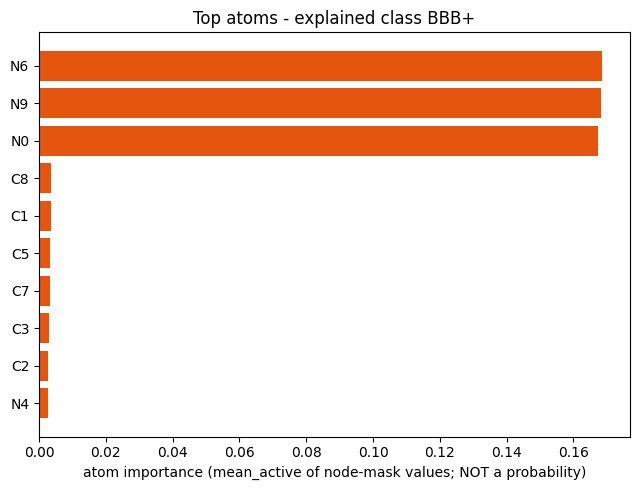

In [32]:
# ---- atom-level result for the first successfully explained molecule ----
FIRST_OK = next((i for i in EXAMPLE_IDS if EXPLAIN_CACHE[i]["status"] == "ok"), None)
def show_atom_scores(test_idx, top_k=12):
    r = EXPLAIN_CACHE[test_idx]
    if r["status"] != "ok": print("no atom scores available:", r["error"]); return
    at = atom_table(r); print(f"Test row {test_idx} | id {r['mol_id']} | SMILES {r['smiles']}")
    print(f"GraphB3 predicted {CLASS_NAME[r['pred']]} (P(BBB+) = {r['p_pos']:.3f}); EXPLAINED CLASS = {CLASS_NAME[r['explained_class']]} (the model's prediction); aggregation = {ATOM_AGG}; normalisation: {r['atom_status']}")
    display(at.round(4))
    top = at.sort_values("importance_raw", ascending=False).head(top_k).iloc[::-1]
    plt.figure(figsize=(6.5, 0.38 * len(top) + 1.2)); plt.barh([f"{e}{i}" for e, i in zip(top["element"], top["atom_idx"])], top["importance_raw"], color="#e6550d")
    plt.xlabel(f"atom importance ({ATOM_AGG} of node-mask values; NOT a probability)"); plt.title(f"Top atoms - explained class {CLASS_NAME[r['explained_class']]}"); plt.tight_layout(); plt.show()
if FIRST_OK is not None: show_atom_scores(FIRST_OK)
else: print("No molecule was explained successfully - see the failure table above.")

## 12. GraphB3 explainability: bond-level importance

The same GNNExplainer run produces an **edge mask** with one value per *directed* edge. PyTorch Geometric stores each undirected chemical bond as two directed edges, and `smiles_to_graph` writes them consecutively: **bond *k* ↔ edges `2k` (begin→end) and `2k+1` (end→begin)**, in RDKit bond order. The mask is mapped back to bonds as follows:

* `bond_scores_from_edge_mask` first **verifies** that the edge list really consists of consecutive reversed pairs and that its length equals 2 × (number of bonds); otherwise it raises an error instead of mis-assigning scores.
* The two directed values of a bond are **averaged** into one bond score (so no bond is counted twice). Both directed values are kept in the bond table; their gap shows how asymmetric the explainer was.
* The RDKit **bond index and the two endpoint atom indices** are preserved in every table and in the 3D viewer.
* Bond scores are min–max normalised **separately from atom scores** (for colouring only; raw scores are always shown).

**Interpretation and limits.** An edge-mask value says how much of a message-passing edge the explainer chose to keep for the model's *predicted* class. It is a property of the trained model and of one stochastic optimisation run — not a bond energy, not a causal effect, and not a probability. If the edge mask is missing, non-finite, identically zero, or does not match the graph, the molecule is reported as *unavailable*.

In [33]:
# ---- self-test of the edge -> bond mapping with SYNTHETIC masks whose correct answer is known (no explainer involved) ----
def _selftest_edge_mapping(mol, graph):
    ei = graph.edge_index.numpy(); nb = mol.GetNumBonds()
    # (a) mask value encodes the endpoint pair; forward edge gets +0.0, backward edge +0.5 of a small offset -> the bond mean must equal the encoded pair value + 0.25 offset
    code_ = lambda i, j: (min(i, j) * 97 + max(i, j) + 1) / (97 * mol.GetNumAtoms() + 1000.0)
    em = np.array([code_(ei[0, e], ei[1, e]) + (0.0 if e % 2 == 0 else 0.5 / 1000.0) for e in range(ei.shape[1])])
    mean, f, bk = bond_scores_from_edge_mask(em, ei, n_bonds=nb)
    for b in mol.GetBonds():
        exp = code_(b.GetBeginAtomIdx(), b.GetEndAtomIdx()) + 0.25 / 1000.0
        assert abs(mean[b.GetIdx()] - exp) < 1e-12, f"bond {b.GetIdx()} received the wrong edge scores"
        assert abs(f[b.GetIdx()] - code_(b.GetBeginAtomIdx(), b.GetEndAtomIdx())) < 1e-12
    assert len(mean) == nb                                                    # one score per bond: nothing double counted
    # (b) a mask of the wrong length / unpaired edges must be rejected
    for bad in (em[:-1], np.append(em, 0.1)):
        try: bond_scores_from_edge_mask(bad, ei); raise AssertionError("size mismatch was not detected")
        except ValueError: pass
n_t = 0
for i in list(dict.fromkeys(list(EXAMPLE_IDS) + list(range(0, len(te_df), max(1, len(te_df) // 40))))):
    if TE_MOLS[i].GetNumBonds() > 0: _selftest_edge_mapping(TE_MOLS[i], test_graphs[i]); n_t += 1
print(f"OK: edge->bond mapping verified on {n_t} test molecules (ring systems, charged and multi-fragment molecules included): correct pairing, one score per bond, mismatches rejected.")

OK: edge->bond mapping verified on 50 test molecules (ring systems, charged and multi-fragment molecules included): correct pairing, one score per bond, mismatches rejected.


Test row 3 | id 227 | 10 bonds = 20 directed edges | explained class = BBB+ | normalisation: ok


,bond_idx,begin_atom,end_atom,atoms,bond_type,edge_i_to_j,edge_j_to_i,importance_raw,importance_norm
0,0,0,1,N0-C1,SINGLE,0.9991,0.0009,0.5000,0.9993
1,1,1,2,C1-C2,AROMATIC,0.0008,0.0009,0.0008,0.0003
2,2,2,3,C2-C3,AROMATIC,0.0008,0.0008,0.0008,0.0002
3,3,3,4,C3-N4,SINGLE,0.0008,0.0007,0.0007,0.0000
4,4,3,5,C3-C5,AROMATIC,0.9995,0.0011,0.5003,0.9998
5,5,5,6,C5-N6,SINGLE,0.0011,0.9993,0.5002,0.9997
6,6,5,7,C5-C7,AROMATIC,0.9995,0.0012,0.5003,0.9999
7,7,7,8,C7-C8,AROMATIC,0.0012,0.9995,0.5004,1.0000
8,8,8,9,C8-N9,SINGLE,0.0010,0.9993,0.5002,0.9996
9,9,8,1,C8-C1,AROMATIC,0.0007,0.0008,0.0007,0.0000


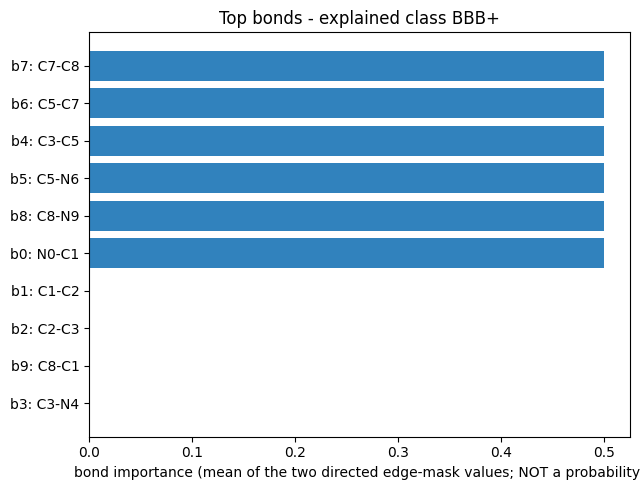

mean |forward - backward| edge-mask gap over the explained molecules: 0.3648  (small = the two directions of a bond were scored consistently)


In [34]:
def show_bond_scores(test_idx, top_k=12):
    r = EXPLAIN_CACHE[test_idx]
    if r["status"] != "ok": print("no bond scores available:", r["error"]); return
    bt = bond_table(r); print(f"Test row {test_idx} | id {r['mol_id']} | {r['mol'].GetNumBonds()} bonds = {len(r['edge_mask'])} directed edges | explained class = {CLASS_NAME[r['explained_class']]} | normalisation: {r['bond_status']}")
    display(bt.round(4))
    top = bt.sort_values("importance_raw", ascending=False).head(top_k).iloc[::-1]
    plt.figure(figsize=(6.5, 0.38 * len(top) + 1.2)); plt.barh([f"b{k}: {a}" for k, a in zip(top["bond_idx"], top["atoms"])], top["importance_raw"], color="#3182bd")
    plt.xlabel("bond importance (mean of the two directed edge-mask values; NOT a probability)"); plt.title(f"Top bonds - explained class {CLASS_NAME[r['explained_class']]}"); plt.tight_layout(); plt.show()
if FIRST_OK is not None:
    show_bond_scores(FIRST_OK)
    asym = np.mean([np.mean(np.abs(r["bond_fwd"] - r["bond_bwd"])) for r in EXPLAIN_CACHE.values() if r["status"] == "ok" and len(r["bond_fwd"])])
    print(f"mean |forward - backward| edge-mask gap over the explained molecules: {asym:.4f}  (small = the two directions of a bond were scored consistently)")

## 13. Integrated interactive 3D molecular explanation

One viewer shows **atom importance and bond importance at the same time**, but with two *independent* encodings so each remains readable on its own:

| | colour | size | hover / click |
|---|---|---|---|
| **Atoms** (spheres) | yellow → red scale of the **atom** importance (min–max normalised over atoms of this molecule) | sphere radius grows with importance (the element sets the base size); the most important atoms also get a translucent halo | atom index, element, raw score, normalised score |
| **Bonds** (cylinders) | light → dark **blue** scale of the **bond** importance (min–max normalised over bonds) | cylinder thickness grows with importance | bond index, endpoint atom indices and elements, bond type, raw score, normalised score |

Element identity is kept by a label (`C5`, `N2`, …) on every atom, so colour is free to encode importance. Atoms and bonds are normalised **separately** because they are different quantities (retained fraction of an atom's input features vs. retained fraction of a message-passing edge) with different value ranges; one shared scale would let one kind dominate the other. Grey = no score available / no variation. The panel above each viewer shows the SMILES, the GraphB3 predicted class, P(BBB+) (uncalibrated sigmoid output), the experimental label, and which class was explained.

**Geometry.** RDKit builds the molecule from the SMILES and embeds a 3D conformer with ETKDGv3 (seed `SEED`) on the hydrogen-complete molecule, then refines it with MMFF94 (UFF if MMFF has no parameters). Fallbacks are tried and **reported** (random-coordinate embedding; as a last resort the flat 2D depiction). Only the heavy atoms are drawn, using the **same atom and bond indices as the GNN graph** (verified, not assumed). Bond order is not drawn (every bond is one cylinder). *The 3D coordinates only display the molecule and its scores: GraphB3 never saw them, and nothing here is a 3D GNN or evidence of a chemical mechanism.* Importance scores are model-explanation values, not probabilities or causal effects.

In [35]:
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image

ATOM_CMAP, BOND_CMAP, CMAP_LO, NO_SCORE = "YlOrRd", "Blues", 0.12, "#b0b0b0"
def score_hex(cmap_name, v):
    """normalised score in [0,1] -> hex colour (the lowest 12% of each colormap is skipped so low scores stay visible on white); NaN -> grey."""
    if v is None or not np.isfinite(v): return NO_SCORE
    return matplotlib.colors.to_hex(matplotlib.colormaps[cmap_name](CMAP_LO + (1 - CMAP_LO) * float(v)))
def gradient_css(cmap_name):
    cm = matplotlib.colormaps[cmap_name]; return "linear-gradient(to right," + ",".join(matplotlib.colors.to_hex(cm(CMAP_LO + (1 - CMAP_LO) * t)) for t in np.linspace(0, 1, 9)) + ")"

# ------------------------------------------------------------------ SMILES-derived molecule -> 3D coordinates for the SAME atom indices as the graph
CONF_CACHE = {}
def make_3d_molecule(mol, seed=SEED):
    """Returns (heavy-atom Mol with one conformer, info). Atom i / bond k of the result are atom i / bond k of `mol` (the graph's molecule)."""
    n = mol.GetNumAtoms(); info = dict(method=None, optimizer="none", is_3d=True, notes=[])
    mh = Chem.AddHs(mol)                                    # hydrogens are appended AFTER the heavy atoms, so heavy-atom indices 0..n-1 are unchanged
    ps = AllChem.ETKDGv3(); ps.randomSeed = int(seed); cid = AllChem.EmbedMolecule(mh, ps)
    if cid == 0: info["method"] = "ETKDGv3"
    else:
        info["notes"].append("ETKDGv3 embedding failed; retrying with random initial coordinates")
        ps2 = AllChem.ETKDGv3(); ps2.randomSeed = int(seed); ps2.useRandomCoords = True; cid = AllChem.EmbedMolecule(mh, ps2)
        if cid == 0: info["method"] = "ETKDGv3 with random initial coordinates (fallback)"
    if cid != 0:                                            # both 3D embeddings failed -> last resort: flat 2D coordinates (clearly reported)
        try:
            AllChem.Compute2DCoords(mh); info.update(method="flat 2D depiction coordinates (3D embedding failed)", is_3d=False)
            info["notes"].append("3D embedding failed twice; the structure is drawn flat")
        except Exception as exc: raise RuntimeError(f"no coordinates could be generated: {exc}") from exc
    else:
        try:
            if AllChem.MMFFHasAllMoleculeParams(mh): info["optimizer"] = "MMFF94 " + ("(converged)" if AllChem.MMFFOptimizeMolecule(mh, maxIters=500) == 0 else "(stopped at 500 iterations)")
            else: info["optimizer"] = "UFF " + ("(converged)" if AllChem.UFFOptimizeMolecule(mh, maxIters=500) == 0 else "(stopped at 500 iterations)"); info["notes"].append("MMFF parameters unavailable; UFF used")
        except Exception as exc: info["notes"].append(f"force-field optimisation failed ({exc}); un-optimised embedding kept")
    conf_h = mh.GetConformer(); vis = Chem.Mol(mol); vis.RemoveAllConformers(); conf = Chem.Conformer(n)
    for i in range(n):
        if mh.GetAtomWithIdx(i).GetAtomicNum() != mol.GetAtomWithIdx(i).GetAtomicNum(): raise RuntimeError(f"atom {i} changed element during embedding")
        conf.SetAtomPosition(i, conf_h.GetAtomPosition(i))
    conf.Set3D(info["is_3d"]); vis.AddConformer(conf, assignId=True)
    if vis.GetNumBonds() != mol.GetNumBonds(): raise RuntimeError("bond count changed")
    return vis, info

# ------------------------------------------------------------------ py3Dmol viewer: atoms = spheres, bonds = cylinders, tooltips via hover/click callbacks
def _tip_js(text, pos):
    return ("function(o,v,ev,c,i){ if(v._tip){v.removeLabel(v._tip);} v._tip=v.addLabel(%s,{position:%s,backgroundColor:'#222222',backgroundOpacity:0.9,fontColor:'white',"
            "fontSize:12,borderThickness:0,showBackground:true,alignment:'bottomLeft'}); v.render(); }" % (json.dumps(text), json.dumps(pos)))
_UNTIP_JS = "function(o,v){ if(v._tip){v.removeLabel(v._tip); v._tip=null; v.render();} }"
_PT = Chem.GetPeriodicTable()

def build_3d_viewer(res, width=760, height=520):
    import py3Dmol
    mol = res["mol"]; idx = res["test_idx"]
    if idx not in CONF_CACHE: CONF_CACHE[idx] = make_3d_molecule(mol)
    vis, info = CONF_CACHE[idx]; conf = vis.GetConformer(); res["conformer_info"] = info
    xyz = lambda i: {"x": conf.GetAtomPosition(i).x, "y": conf.GetAtomPosition(i).y, "z": conf.GetAtomPosition(i).z}
    view = py3Dmol.view(width=width, height=height); view.setBackgroundColor("white")
    for b in mol.GetBonds():                                                                # ---- bonds
        k, i, j = b.GetIdx(), b.GetBeginAtomIdx(), b.GetEndAtomIdx(); s, nrm = res["bond_raw"][k], res["bond_norm"][k]
        radius = 0.07 + 0.17 * nrm if np.isfinite(nrm) else 0.10
        mid = {a: (xyz(i)[a] + xyz(j)[a]) / 2 for a in "xyz"}
        tip = f"Bond {k}: {mol.GetAtomWithIdx(i).GetSymbol()}{i} - {mol.GetAtomWithIdx(j).GetSymbol()}{j} ({b.GetBondType()}) | importance {s:.4f} | normalised {nrm:.2f}" if np.isfinite(nrm) else f"Bond {k}: {mol.GetAtomWithIdx(i).GetSymbol()}{i} - {mol.GetAtomWithIdx(j).GetSymbol()}{j} | importance {s:.4f} | no colour scale"
        view.addCylinder({"start": xyz(i), "end": xyz(j), "radius": radius, "color": score_hex(BOND_CMAP, nrm), "fromCap": 1, "toCap": 1,
                          "hoverable": True, "hover_callback": _tip_js(tip, mid), "unhover_callback": _UNTIP_JS, "clickable": True, "callback": _tip_js(tip, mid)})
    for a in mol.GetAtoms():                                                                # ---- atoms
        i = a.GetIdx(); s, nrm = res["atom_raw"][i], res["atom_norm"][i]; base = 0.22 * _PT.GetRvdw(a.GetAtomicNum())
        radius = base * (0.80 + 0.45 * nrm) if np.isfinite(nrm) else base; col = score_hex(ATOM_CMAP, nrm); pos = xyz(i)
        tip = f"Atom {i}: {a.GetSymbol()} | importance {s:.4f} | normalised {nrm:.2f}" if np.isfinite(nrm) else f"Atom {i}: {a.GetSymbol()} | importance {s:.4f} | no colour scale"
        if np.isfinite(nrm) and nrm >= 0.75: view.addSphere({"center": pos, "radius": radius * 1.7, "color": col, "opacity": 0.22})       # halo for the most important atoms
        view.addSphere({"center": pos, "radius": radius, "color": col, "hoverable": True, "hover_callback": _tip_js(tip, pos), "unhover_callback": _UNTIP_JS,
                        "clickable": True, "callback": _tip_js(tip, pos)})
        view.addLabel(f"{a.GetSymbol()}{i}", {"position": pos, "fontSize": 12, "fontColor": "black", "showBackground": True, "backgroundColor": "white", "backgroundOpacity": 0.55, "borderThickness": 0, "alignment": "center"})
    view.zoomTo(); return view

# ------------------------------------------------------------------ information panel + legends
def info_html(res):
    e = html.escape; i = res["test_idx"]; pr = PRED_DF.iloc[i]
    ex = CLASS_NAME[res["explained_class"]]
    return ('<div style="font-family:sans-serif;font-size:13px;color:#222;background:#fff;border:1px solid #bbb;border-radius:8px;padding:10px 14px;max-width:780px;line-height:1.5">'
            f'<b>Test row {i}</b> &middot; molecule id <b>{e(str(res["mol_id"]))}</b><br>SMILES: <code style="word-break:break-all">{e(res["smiles"])}</code><br>'
            f'<b>GraphB3</b> predicted class: <b>{CLASS_NAME[res["pred"]]}</b> &nbsp;|&nbsp; P(BBB+) = {res["p_pos"]:.3f} <span style="color:#777">(uncalibrated sigmoid output)</span> &nbsp;|&nbsp; '
            f'experimental label: <b>{CLASS_NAME[res["y_true"]]}</b> &nbsp;{"(correct)" if res["pred"] == res["y_true"] else "(<b>incorrect</b>)"}<br>'
            f'<b>Extra Trees</b> predicted class: <b>{CLASS_NAME[int(pr["pred_extratrees"])]}</b> &nbsp;|&nbsp; P(BBB+) = {pr["p_extratrees"]:.3f}<br>'
            f'<b>Explained class: {ex}</b> &mdash; GNNExplainer (<code>explanation_type="model"</code>) explains the class the model <i>predicted</i>, not the experimental label.</div>')

def legend_html(res):
    a_lo, a_hi = np.nanmin(res["atom_raw"]), np.nanmax(res["atom_raw"]); b_lo, b_hi = (np.nanmin(res["bond_raw"]), np.nanmax(res["bond_raw"])) if len(res["bond_raw"]) else (np.nan, np.nan)
    notes = []
    if res["atom_status"] != "ok": notes.append("atoms: " + res["atom_status"])
    if res["bond_status"] != "ok": notes.append("bonds: " + res["bond_status"])
    ci = res.get("conformer_info", {}); conf_txt = f'{ci.get("method")}; {ci.get("optimizer")}' + ("".join("; " + n for n in ci.get("notes", [])))
    bar = lambda cm_: f'<div style="height:14px;width:240px;border:1px solid #999;background:{gradient_css(cm_)}"></div>'
    return ('<div style="font-family:sans-serif;font-size:12px;color:#222;background:#fff;border:1px solid #bbb;border-radius:8px;padding:8px 14px;max-width:780px;line-height:1.5;margin-top:4px">'
            '<table style="border-collapse:collapse"><tr><td style="padding-right:18px"><b>Atom importance</b> (sphere colour &amp; size)</td><td>'
            f'{bar(ATOM_CMAP)}<div style="display:flex;justify-content:space-between;width:240px"><span>low (0)<br>raw {a_lo:.3f}</span><span style="text-align:right">high (1)<br>raw {a_hi:.3f}</span></div></td></tr>'
            '<tr><td style="padding-right:18px;padding-top:6px"><b>Bond importance</b> (cylinder colour &amp; thickness)</td><td style="padding-top:6px">'
            f'{bar(BOND_CMAP)}<div style="display:flex;justify-content:space-between;width:240px"><span>low (0)<br>raw {b_lo:.3f}</span><span style="text-align:right">high (1)<br>raw {b_hi:.3f}</span></div></td></tr></table>'
            f'<div style="margin-top:6px">Grey = no score / no variation. Atoms and bonds are normalised <b>separately</b>, within this molecule (colour only; raw values in the tooltips). {html.escape("; ".join(notes))}</div>'
            f'<div style="color:#555">Atom score = {ATOM_AGG} of GNNExplainer node-mask values; bond score = mean of the two directed edge-mask values. Hover or click an atom / bond for details; drag to rotate, scroll to zoom. '
            f'Geometry: {html.escape(conf_txt)} (display only; GraphB3 does not use 3D coordinates). Scores are model-explanation values, not probabilities or causal effects.</div></div>')

# ------------------------------------------------------------------ static 2D drawing with the SAME scores (fallback + gallery)
def draw_explanation_2d(res, size=420):
    mol = res["mol"]; a_cols = {a.GetIdx(): matplotlib.colors.to_rgb(score_hex(ATOM_CMAP, res["atom_norm"][a.GetIdx()])) for a in mol.GetAtoms()}
    b_cols = {b.GetIdx(): matplotlib.colors.to_rgb(score_hex(BOND_CMAP, res["bond_norm"][b.GetIdx()])) for b in mol.GetBonds()}
    radii = {i: 0.25 + (0.30 * res["atom_norm"][i] if np.isfinite(res["atom_norm"][i]) else 0.0) for i in a_cols}
    d = rdMolDraw2D.MolDraw2DCairo(size, size); o = d.drawOptions(); o.clearBackground = True; o.setBackgroundColour((1, 1, 1)); o.addAtomIndices = True; o.highlightBondWidthMultiplier = 14
    d.DrawMolecule(mol, highlightAtoms=list(a_cols), highlightAtomColors=a_cols, highlightAtomRadii=radii, highlightBonds=list(b_cols), highlightBondColors=b_cols); d.FinishDrawing()
    return Image.open(io.BytesIO(d.GetDrawingText())).convert("RGB")

# ------------------------------------------------------------------ main entry point: show one molecule (explains it on demand if needed)
def show_explanation(test_idx, width=760, height=520, explain_if_missing=True):
    test_idx = int(test_idx)
    if not 0 <= test_idx < len(te_df): raise IndexError(f"test row {test_idx} is outside 0..{len(te_df)-1}")
    res = EXPLAIN_CACHE.get(test_idx)
    if res is None:
        if not explain_if_missing: raise KeyError(f"test row {test_idx} has not been explained yet")
        print(f"Running GNNExplainer for test row {test_idx} ({EXPLAINER_EPOCHS} epochs) ..."); res = explain_test_molecule(test_idx); EXPLAIN_CACHE[test_idx] = res
    if res["status"] != "ok":
        display(HTML(f'<div style="font-family:sans-serif;border:1px solid #c62828;color:#c62828;padding:8px;border-radius:6px">No explanation available for test row {test_idx} (id {html.escape(str(res["mol_id"]))}): {html.escape(res["error"])}</div>')); return
    display(HTML(info_html(res)))
    shown = False
    if HAVE_PY3DMOL:
        try: build_3d_viewer(res, width, height).show(); shown = True
        except Exception as exc:
            FAILURES.append(dict(test_row=test_idx, mol_id=res["mol_id"], stage="3D viewer", error=f"{type(exc).__name__}: {exc}")); print(f"3D viewer failed ({type(exc).__name__}: {exc}); showing the static 2D drawing instead.")
    if not shown:
        try: display(draw_explanation_2d(res, 520))
        except Exception as exc: FAILURES.append(dict(test_row=test_idx, mol_id=res["mol_id"], stage="2D drawing", error=f"{type(exc).__name__}: {exc}")); print(f"2D drawing also failed: {exc}")
    display(HTML(legend_html(res)))

# ---- consistency check: what the viewer draws == the actual explanation scores, indexed like the graph ----
for _i, _r in EXPLAIN_CACHE.items():
    if _r["status"] != "ok": continue
    _vis, _ = CONF_CACHE.setdefault(_i, make_3d_molecule(_r["mol"]))
    assert [a.GetSymbol() for a in _vis.GetAtoms()] == [a.GetSymbol() for a in _r["mol"].GetAtoms()] and all(
        (b1.GetBeginAtomIdx(), b1.GetEndAtomIdx()) == (b2.GetBeginAtomIdx(), b2.GetEndAtomIdx()) for b1, b2 in zip(_vis.GetBonds(), _r["mol"].GetBonds()))
    assert len(_r["atom_raw"]) == _vis.GetNumAtoms() and len(_r["bond_raw"]) == _vis.GetNumBonds()
print("OK: for every explained molecule the 3D structure has the same atom order, bond order and endpoints as the GNN graph, and one score per atom / bond.")
info_tab = pd.DataFrame([dict(test_row=i, mol_id=EXPLAIN_CACHE[i]["mol_id"] if i in EXPLAIN_CACHE else "", geometry=CONF_CACHE[i][1]["method"], optimiser=CONF_CACHE[i][1]["optimizer"], notes="; ".join(CONF_CACHE[i][1]["notes"])) for i in CONF_CACHE])
display(info_tab)

OK: for every explained molecule the 3D structure has the same atom order, bond order and endpoints as the GNN graph, and one score per atom / bond.


,test_row,mol_id,geometry,optimiser,notes
0,3,227,ETKDGv3,MMFF94 (converged),
1,1,61,ETKDGv3,MMFF94 (converged),
2,0,60,ETKDGv3,MMFF94 (converged),
3,5,303,ETKDGv3,MMFF94 (converged),
4,2,115,ETKDGv3,MMFF94 (converged),
5,8,338,ETKDGv3,MMFF94 (converged),
6,151,2304,ETKDGv3,MMFF94 (converged),
7,159,2507,ETKDGv3,MMFF94 (converged),
8,7,316,ETKDGv3,MMFF94 (converged),
9,15,400,ETKDGv3,MMFF94 (converged),


### Interactive viewer — first explained molecule
Rotate with the mouse, zoom with the scroll wheel, **hover or click** atoms and bonds for their scores. (If the 3D scene does not appear — for example in a notebook front-end that blocks the 3Dmol.js script — the cell falls back to a static 2D drawing with the same scores.)

In [37]:
import importlib.util

HAVE_PY3DMOL = importlib.util.find_spec("py3Dmol") is not None
HAVE_WIDGETS = importlib.util.find_spec("ipywidgets") is not None

In [38]:
if FIRST_OK is not None: show_explanation(FIRST_OK)
else: print("No molecule was explained successfully; nothing to show.")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Atom importance (sphere colour & size),low (0)raw 0.003high (1)raw 0.168
Bond importance (cylinder colour & thickness),low (0)raw 0.001high (1)raw 0.500


### Choose any molecule (selector)
Pick one of the explained examples, or type **any test-row number** (0 … N−1) and press *Explain / show*: molecules that are not cached yet are explained on demand (a few seconds to a minute on CPU for 2000 explainer epochs; lower `EXPLAINER_EPOCHS` to speed up). The selector lives entirely inside the notebook. If `ipywidgets` is not available, call `show_explanation(<test row>)` instead. If the 3D scene does not render inside the widget in your front-end, call `show_explanation(...)` in a normal cell (the cell above shows that this works).

In [39]:
def make_selector():
    import ipywidgets as W
    def _label(i):
        r = EXPLAIN_CACHE[i]; return f"row {i} | id {r['mol_id']} | true {CLASS_NAME[r['y_true']]} | GraphB3 {CLASS_NAME[r['pred']] if 'pred' in r else '?'} | {EXAMPLE_TAGS.get(i, 'user-selected')}"
    dd = W.Dropdown(options=[(_label(i), i) for i in EXPLAIN_CACHE], description="Explained:", layout=W.Layout(width="780px"), style={"description_width": "80px"})
    num = W.BoundedIntText(value=int(FIRST_OK or 0), min=0, max=len(te_df) - 1, description="Test row:", style={"description_width": "80px"}, layout=W.Layout(width="200px"))
    btn = W.Button(description="Explain / show", button_style="primary"); out = W.Output()
    def _show(i):
        with out:
            out.clear_output(wait=True)
            try: show_explanation(i)
            except Exception as exc: FAILURES.append(dict(test_row=i, mol_id="", stage="selector", error=f"{type(exc).__name__}: {exc}")); print(f"ERROR: {type(exc).__name__}: {exc}")
        if i in EXPLAIN_CACHE and EXPLAIN_CACHE[i]["status"] == "ok" and i not in [v for _, v in dd.options]:
            dd.options = list(dd.options) + [(_label(i), i)]
    dd.observe(lambda ch: (num.__setattr__("value", ch["new"]), _show(ch["new"])) if ch["name"] == "value" and ch["new"] is not None else None, names="value")
    btn.on_click(lambda _b: _show(num.value))
    display(W.VBox([dd, W.HBox([num, btn]), out]))
    if FIRST_OK is not None: _show(FIRST_OK)

if HAVE_WIDGETS and EXPLAIN_CACHE:
    make_selector()
else:
    print("Selector unavailable (" + ("ipywidgets not installed" if not HAVE_WIDGETS else "no explained molecules") + "). Use show_explanation(<test row>); explained rows:", list(EXPLAIN_CACHE))

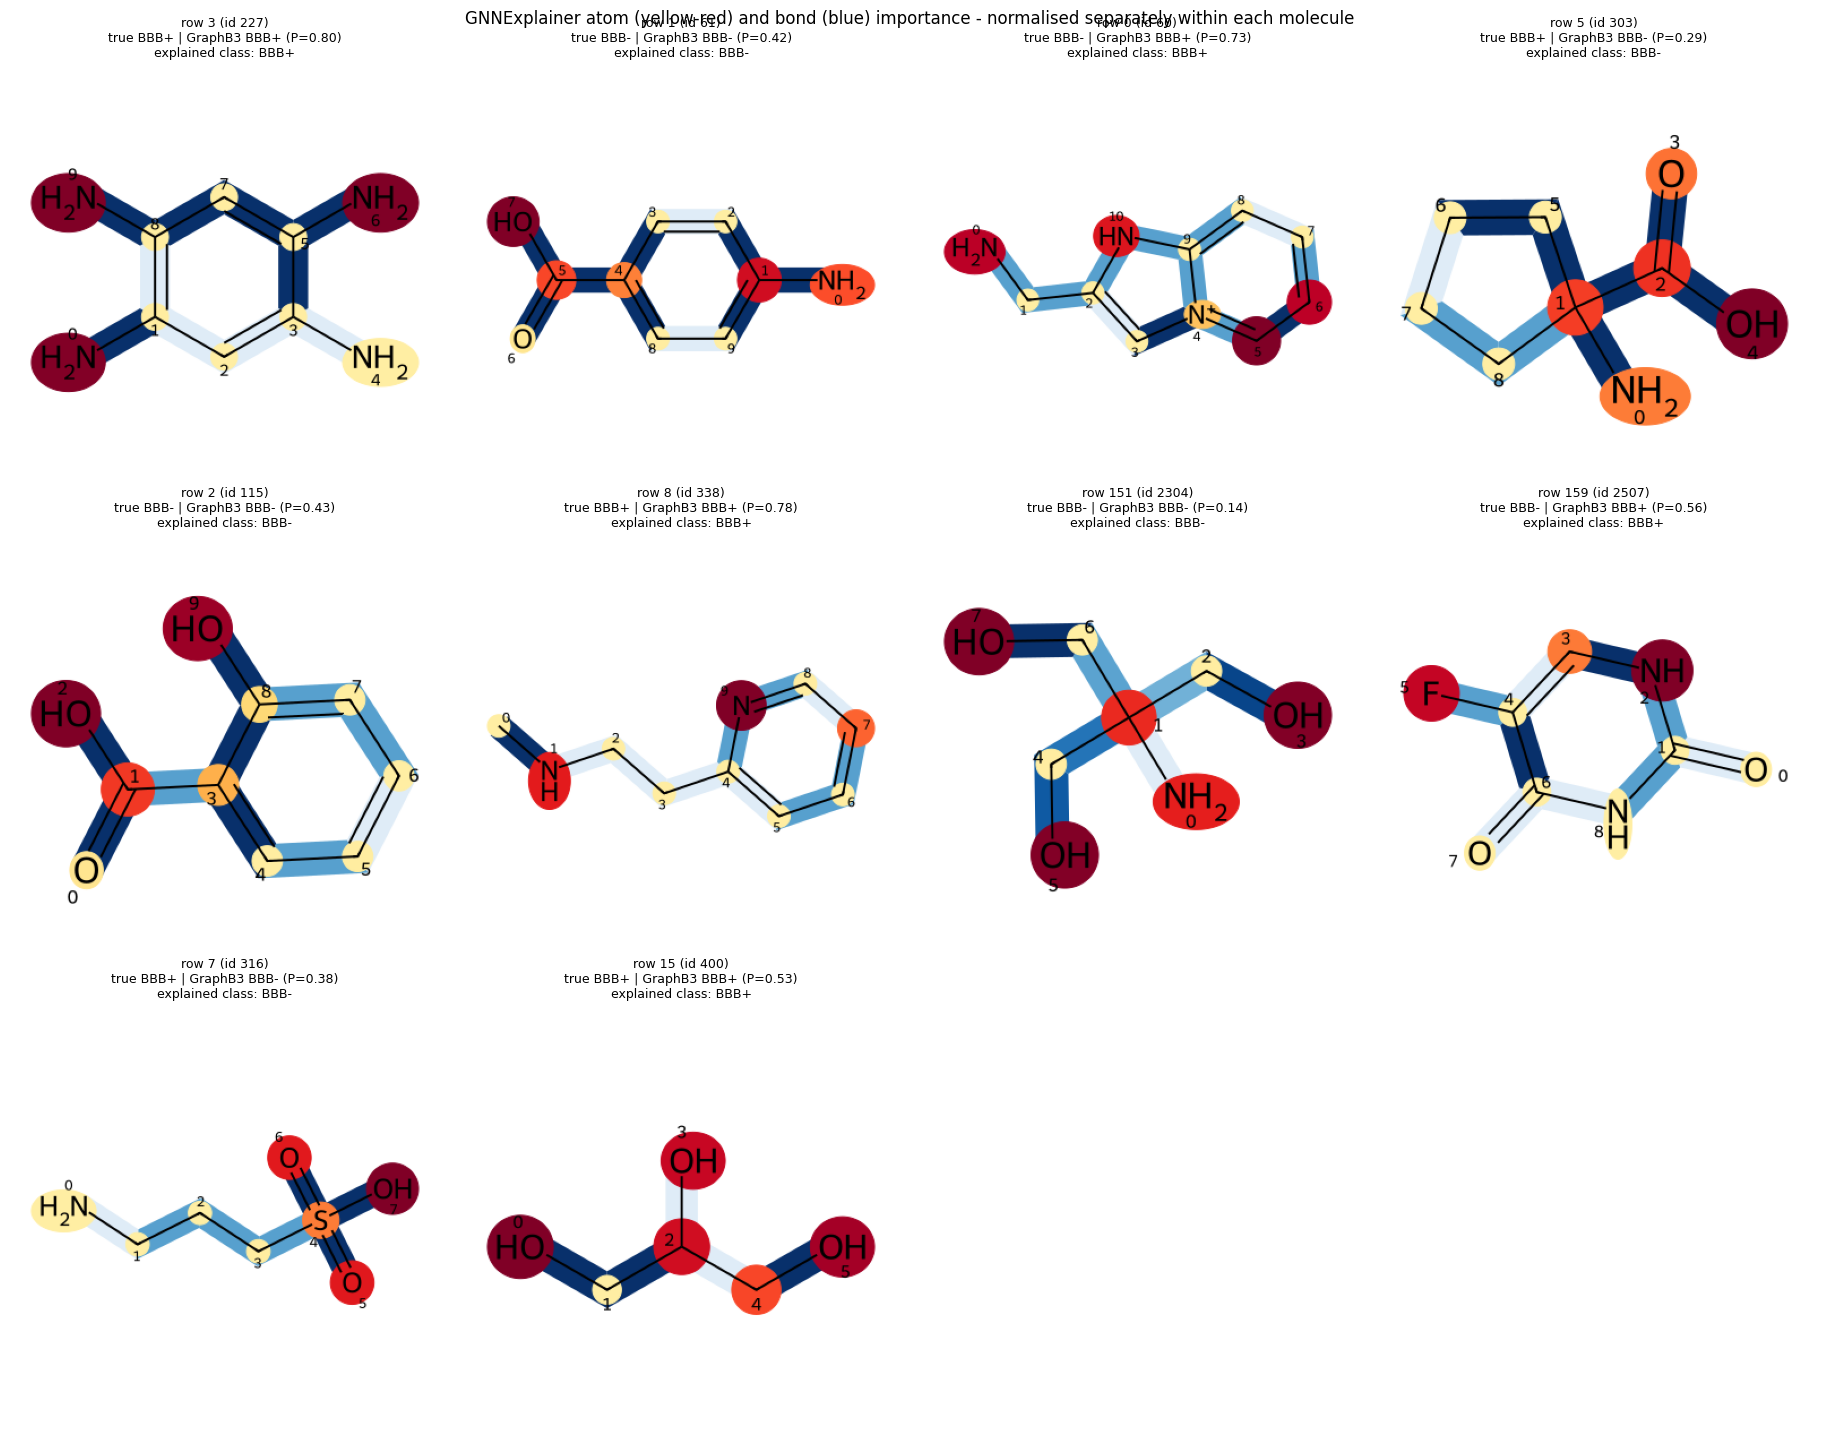

In [40]:
# ---- static gallery of all explained molecules (2D, same scores and colour scales; complements the interactive viewer) ----
ok_ids = [i for i in EXPLAIN_CACHE if EXPLAIN_CACHE[i]["status"] == "ok"]
if ok_ids:
    cols = min(4, len(ok_ids)); rows_n = int(np.ceil(len(ok_ids) / cols)); fig, axes = plt.subplots(rows_n, cols, figsize=(4.6 * cols, 4.9 * rows_n)); axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, i in zip(axes, ok_ids):
        r = EXPLAIN_CACHE[i]
        try: ax.imshow(draw_explanation_2d(r, 380))
        except Exception as exc: ax.text(0.5, 0.5, f"2D drawing failed:\n{exc}", ha="center"); FAILURES.append(dict(test_row=i, mol_id=r["mol_id"], stage="2D gallery", error=str(exc)))
        ax.set_title(f"row {i} (id {r['mol_id']})\ntrue {CLASS_NAME[r['y_true']]} | GraphB3 {CLASS_NAME[r['pred']]} (P={r['p_pos']:.2f})\nexplained class: {CLASS_NAME[r['explained_class']]}", fontsize=9)
    fig.suptitle("GNNExplainer atom (yellow-red) and bond (blue) importance - normalised separately within each molecule", fontsize=12); plt.tight_layout(); plt.show()

## 14. Extra Trees descriptor explainability

Extra Trees works on **whole-molecule descriptors**, so its explanations are about *descriptors*, not atoms or bonds. Descriptor importance is **never mapped onto atoms or bonds** here, and a globally important descriptor does not necessarily explain any individual prediction. Every importance value is tied to its descriptor name through `ET_KEPT` (the names the fitted pipeline kept) or the raw column names (permutation importance).

### A. Built-in (impurity-based) importance
`feature_importances_` of the fitted forest: the average reduction of Gini impurity that splits on a descriptor achieve, normalised to sum to 1. It is computed **on training data**, can favour continuous / high-variance descriptors, and **splits credit among correlated descriptors** — so read it as a rough ranking, not a precise measure. Descriptors removed by the pipeline (constant or |r| > 0.95 with a kept one) are listed with importance 0 and the reason.

### B. Permutation importance (held-out data)
Each descriptor column is shuffled (`PERM_REPEATS` times, seed `RANDOM_STATE`) in *held-out* data and the drop in a score is measured **through the whole fitted pipeline** (so preprocessing is applied after shuffling). A large drop means the fitted model **depends on that descriptor under this evaluation procedure**; ~0 means the model does not use it (or, for correlated descriptors, that the information is available elsewhere). Scores used: **ROC-AUC** (threshold-free; the ranking criterion) and MCC at threshold 0.5. The **primary** analysis uses the **validation split** — data that did not fit the model and that played no role in tuning. As a post-hoc check (`PERM_ON_TEST`) it is repeated on the **test set**, strictly as interpretability: those numbers are never fed back into tuning, feature selection or model selection. Descriptors dropped by the pipeline have importance exactly 0 by construction.

A. Built-in importance (mean decrease in impurity, training data) - top 15 descriptors; the last two columns are DESCRIPTIVE class medians in the training split, not model output


,descriptor,group,built-in importance,status,meaning,training median BBB+,training median BBB-
rank,,,,,,,
1,TPSA,lipo_polar,0.1158,used,topological polar surface area (polar N/O atom...,54.4550,115.0600
2,NumHeteroatoms,hbond,0.0950,used,"number of non-C, non-H atoms",5.0000,9.0000
3,nCarboxylicAcid,charge_comp,0.0867,used,carboxylic-acid groups (SMARTS),0.0000,0.0000
4,NumHDonors,hbond,0.0814,used,number of hydrogen-bond donors,1.0000,3.0000
5,NumHAcceptors,hbond,0.0656,used,number of hydrogen-bond acceptors,4.0000,6.0000
6,nO,charge_comp,0.0467,used,oxygen atom count,2.0000,5.0000
7,nN,charge_comp,0.0403,used,nitrogen atom count,1.0000,3.0000
8,MolLogP,lipo_polar,0.0381,used,Crippen logP - calculated lipophilicity (octan...,3.0311,1.5522
9,NumAliphaticRings,rings,0.0374,used,number of non-aromatic rings,2.0000,2.0000


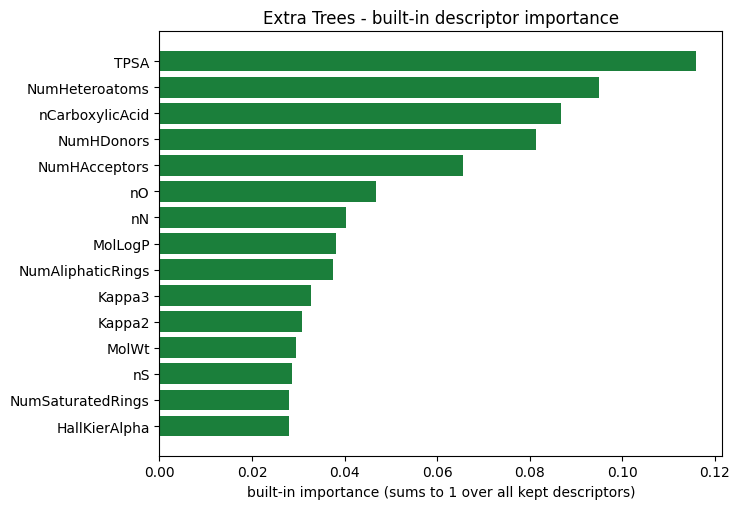

group totals of built-in importance:


,built-in importance
group,
charge_comp,0.2764
hbond,0.2420
lipo_polar,0.1539
flex_shape,0.1174
rings,0.1047
topology,0.0761
size,0.0295


In [41]:
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

# ---------------- A. built-in importance, tied to descriptor names ----------------
imp_builtin = dict(zip(ET_KEPT, et_clf.feature_importances_)); assert abs(sum(imp_builtin.values()) - 1.0) < 1e-6
status = {n: "used" for n in ET_KEPT}; status.update({n: "dropped: constant in training data" for n in ET_CONST_DROPPED}); status.update({n: f"dropped: |r| > 0.95 with {k}" for n, k in ET_CORR_DROPPED.items()})
med_pos, med_neg = Xtr[ytr == 1].median(), Xtr[ytr == 0].median()
ET_IMP_TABLE = pd.DataFrame({"descriptor": NAMES, "group": [GROUPS[n] for n in NAMES], "built-in importance": [imp_builtin.get(n, 0.0) for n in NAMES],
                             "status": [status[n] for n in NAMES], "meaning": [DESC_MEANING[n] for n in NAMES],
                             "training median BBB+": [med_pos[n] for n in NAMES], "training median BBB-": [med_neg[n] for n in NAMES]})
ET_IMP_TABLE = ET_IMP_TABLE.sort_values("built-in importance", ascending=False).reset_index(drop=True); ET_IMP_TABLE.index += 1; ET_IMP_TABLE.index.name = "rank"
print("A. Built-in importance (mean decrease in impurity, training data) - top 15 descriptors; the last two columns are DESCRIPTIVE class medians in the training split, not model output")
display(ET_IMP_TABLE.head(15).round(4))
top = ET_IMP_TABLE.head(15).iloc[::-1]; plt.figure(figsize=(7.5, 5.2)); plt.barh(top["descriptor"], top["built-in importance"], color="#1b7f3b")
plt.xlabel("built-in importance (sums to 1 over all kept descriptors)"); plt.title("Extra Trees - built-in descriptor importance"); plt.tight_layout(); plt.show()
print("group totals of built-in importance:"); display(ET_IMP_TABLE.groupby("group")["built-in importance"].sum().sort_values(ascending=False).round(4).to_frame())

permutation importance on validation data: 1206 molecules, 10 repeats [64s]
permutation importance on test, post-hoc data: 1771 molecules, 10 repeats [68s]

B. Permutation importance, ranked by the validation AUC drop (mean and SD over repeats; larger = the model depends more on this descriptor). Only descriptors the model uses are ranked here:


,descriptor,group,AUC drop mean (validation),AUC drop sd (validation),MCC drop mean (validation),MCC drop sd (validation),"AUC drop mean (test, post-hoc)","AUC drop sd (test, post-hoc)",status
perm. rank,,,,,,,,,
1,TPSA,lipo_polar,0.0297,0.0044,0.0108,0.0072,0.0237,0.0016,used
2,NumHDonors,hbond,0.0282,0.0029,0.0582,0.0095,0.0251,0.0030,used
3,nCarboxylicAcid,charge_comp,0.0238,0.0027,0.0604,0.0072,0.0234,0.0022,used
4,NumAliphaticRings,rings,0.0170,0.0015,0.0109,0.0064,0.0141,0.0022,used
5,nBasicAmine,charge_comp,0.0151,0.0014,0.0142,0.0047,0.0100,0.0006,used
6,NumHeteroatoms,hbond,0.0151,0.0024,0.0078,0.0057,0.0097,0.0014,used
7,nN,charge_comp,0.0108,0.0014,0.0178,0.0066,0.0079,0.0015,used
8,NumSaturatedRings,rings,0.0091,0.0011,0.0049,0.0034,0.0040,0.0011,used
9,nO,charge_comp,0.0085,0.0014,0.0038,0.0042,0.0045,0.0011,used


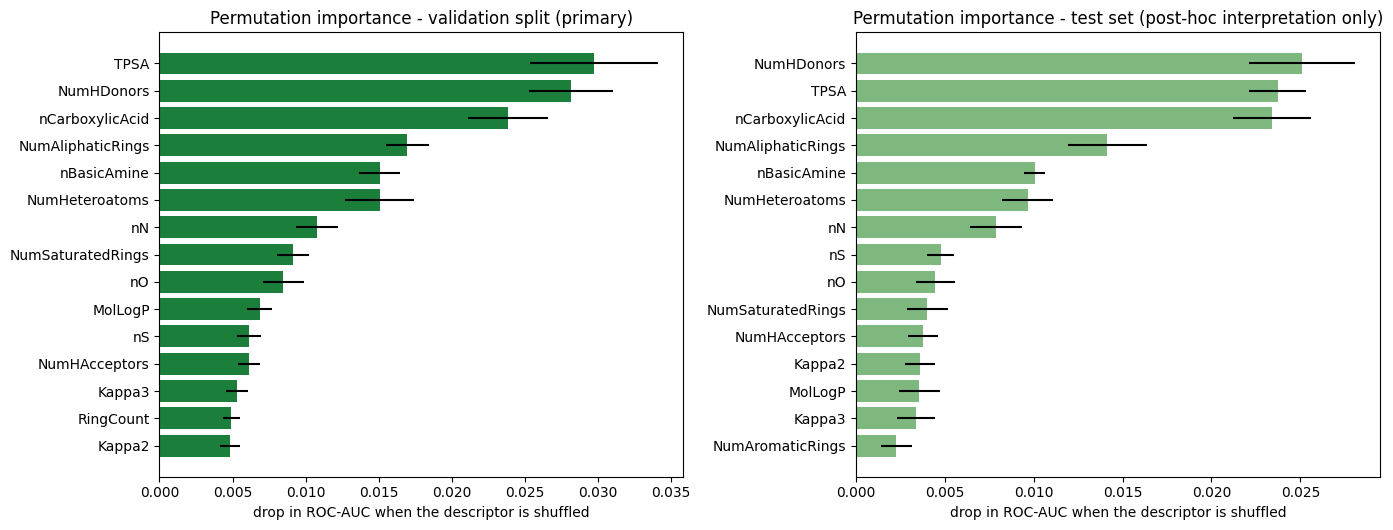

Spearman rank correlation, built-in vs validation-permutation importance over the 27 used descriptors: 0.821
Spearman rank correlation, validation vs test permutation importance: 0.969


In [42]:
# ---------------- B. permutation importance on HELD-OUT data (validation = primary, test = post-hoc) ----------------
SCORING = {"roc_auc": "roc_auc", "mcc": mcc_scorer}
def perm_table(X, y, label):
    t0 = time.time(); pi = permutation_importance(et_model, X, y, scoring=SCORING, n_repeats=PERM_REPEATS, random_state=RANDOM_STATE, n_jobs=1)
    cols = list(X.columns); assert cols == NAMES
    df = pd.DataFrame({"descriptor": cols, f"AUC drop mean ({label})": pi["roc_auc"].importances_mean, f"AUC drop sd ({label})": pi["roc_auc"].importances_std,
                       f"MCC drop mean ({label})": pi["mcc"].importances_mean, f"MCC drop sd ({label})": pi["mcc"].importances_std})
    print(f"permutation importance on {label} data: {len(y)} molecules, {PERM_REPEATS} repeats [{time.time()-t0:.0f}s]"); return df

PERM_VAL = perm_table(Xva, yva, "validation")
ET_PERM = ET_IMP_TABLE.reset_index().merge(PERM_VAL, on="descriptor")
if PERM_ON_TEST: ET_PERM = ET_PERM.merge(perm_table(X_te, y_test, "test, post-hoc"), on="descriptor")
ET_PERM = ET_PERM.sort_values("AUC drop mean (validation)", ascending=False).reset_index(drop=True); ET_PERM.index += 1; ET_PERM.index.name = "perm. rank"
shown = ["descriptor", "group", "AUC drop mean (validation)", "AUC drop sd (validation)", "MCC drop mean (validation)", "MCC drop sd (validation)"] + (["AUC drop mean (test, post-hoc)", "AUC drop sd (test, post-hoc)"] if PERM_ON_TEST else []) + ["status"]
ET_PERM_USED = ET_PERM[ET_PERM["status"] == "used"]          # descriptors dropped by the pipeline are 0 by construction and are listed in ET_PERM only
print("\nB. Permutation importance, ranked by the validation AUC drop (mean and SD over repeats; larger = the model depends more on this descriptor). Only descriptors the model uses are ranked here:")
display(ET_PERM_USED[shown].head(15).round(4))

fig, ax = plt.subplots(1, 2 if PERM_ON_TEST else 1, figsize=(14 if PERM_ON_TEST else 7.5, 5.4)); ax = np.atleast_1d(ax)
for a, (col, sd, ttl, c) in zip(ax, [("AUC drop mean (validation)", "AUC drop sd (validation)", "validation split (primary)", "#1b7f3b"), ("AUC drop mean (test, post-hoc)", "AUC drop sd (test, post-hoc)", "test set (post-hoc interpretation only)", "#7fb87f")][:len(ax)]):
    t = ET_PERM_USED.sort_values(col, ascending=False).head(15).iloc[::-1]; a.barh(t["descriptor"], t[col], xerr=t[sd], color=c); a.set(xlabel="drop in ROC-AUC when the descriptor is shuffled", title=f"Permutation importance - {ttl}")
plt.tight_layout(); plt.show()

used = ET_PERM[ET_PERM["status"] == "used"]; rho = spearmanr(used["built-in importance"], used["AUC drop mean (validation)"])
print(f"Spearman rank correlation, built-in vs validation-permutation importance over the {len(used)} used descriptors: {rho.correlation:.3f}")
if PERM_ON_TEST: print(f"Spearman rank correlation, validation vs test permutation importance: {spearmanr(used['AUC drop mean (validation)'], used['AUC drop mean (test, post-hoc)']).correlation:.3f}")

### C. Interpretation of the important descriptors
The table below joins, for the ten descriptors with the largest validation permutation importance, their **definition** (from the descriptor code in section 6) with the built-in rank and the descriptive class medians in the training data. Read it with these limits in mind:
* The definitions come from RDKit: e.g. TPSA and hydrogen-bond donor/acceptor counts describe *polarity / hydrogen bonding*, molecular weight / heavy-atom count / surface area describe *size*, MolLogP describes calculated *lipophilicity*, and the ring / Kappa / BertzCT / BalabanJ descriptors describe *shape and topological complexity*. Descriptors in the same family are often correlated, so importance can be shared or hidden among them.
* "Important" means the *fitted model depends on it* (and on the evaluation data used); it is **not** evidence that the descriptor *causes* BBB permeability. The class medians are plain descriptive statistics of the training data, not model effects.
* The ranking can change with another split, seed, or tuning draw, and a **global** ranking says nothing certain about any **single** molecule — hence the per-molecule sensitivity in D.

In [43]:
interp = ET_PERM_USED.head(10).copy(); interp["built-in rank"] = [int(ET_IMP_TABLE.index[ET_IMP_TABLE["descriptor"] == d][0]) for d in interp["descriptor"]]
display(interp[["descriptor", "group", "meaning", "AUC drop mean (validation)", "built-in rank", "training median BBB+", "training median BBB-"]].round(3))
zero_used = ET_PERM[(ET_PERM["status"] == "used") & (ET_PERM["AUC drop mean (validation)"] <= 0)]["descriptor"].tolist()
print("used descriptors whose shuffling did not reduce validation AUC (model does not depend on them here):", zero_used or "none")

,descriptor,group,meaning,AUC drop mean (validation),built-in rank,training median BBB+,training median BBB-
perm. rank,,,,,,,
1,TPSA,lipo_polar,topological polar surface area (polar N/O atom...,0.030,1,54.455,115.060
2,NumHDonors,hbond,number of hydrogen-bond donors,0.028,4,1.000,3.000
3,nCarboxylicAcid,charge_comp,carboxylic-acid groups (SMARTS),0.024,3,0.000,0.000
4,NumAliphaticRings,rings,number of non-aromatic rings,0.017,9,2.000,2.000
5,nBasicAmine,charge_comp,"basic-amine groups (SMARTS, excludes amides / ...",0.015,19,1.000,0.000
6,NumHeteroatoms,hbond,"number of non-C, non-H atoms",0.015,2,5.000,9.000
7,nN,charge_comp,nitrogen atom count,0.011,7,1.000,3.000
8,NumSaturatedRings,rings,number of saturated rings,0.009,14,1.000,1.000
9,nO,charge_comp,oxygen atom count,0.008,6,2.000,5.000


used descriptors whose shuffling did not reduce validation AUC (model does not depend on them here): none


### D. Per-molecule descriptor sensitivity (individual-prediction view; method and assumptions)
For one test molecule, each descriptor in turn is **replaced by its training-set median** while all other descriptors keep their values, and the change in Extra Trees' P(BBB+) is recorded: *change = P(BBB+) with the real value − P(BBB+) with the median*. It is a **one-at-a-time occlusion**, not SHAP and not a Shapley decomposition. Assumptions and limits: the median is an arbitrary reference ("typical" molecule), the changes **do not add up** to the prediction, correlated descriptors may mask or share effects (an unrealistic combination of values can be produced), and descriptors dropped by the pipeline have change exactly 0 because the model never sees them. It describes the **model's** local behaviour for that molecule only.

In [44]:
TRAIN_MEDIAN = Xtr.median()
def et_local_sensitivity(test_idx):
    row = X_te.iloc[[int(test_idx)]]; base = float(et_proba(row)[0]); mod = pd.concat([row] * len(NAMES), ignore_index=True)
    for k, n in enumerate(NAMES): mod.loc[k, n] = TRAIN_MEDIAN[n]
    p_med = et_proba(mod)
    df = pd.DataFrame({"descriptor": NAMES, "value": row.iloc[0].values, "training median": TRAIN_MEDIAN.values, "P(BBB+) with median": p_med, "change": base - p_med})
    df["abs change"] = df["change"].abs(); return base, df.sort_values("abs change", ascending=False).reset_index(drop=True).drop(columns="abs change")

demo = FIRST_OK if FIRST_OK is not None else (EXAMPLE_IDS[0] if EXAMPLE_IDS else 0)
base, loc = et_local_sensitivity(demo)
print(f"Test row {demo} | id {te_df['mol_id'].iloc[demo]} | {te_df['SMILES'].iloc[demo]}\nExtra Trees P(BBB+) = {base:.3f} (predicted {CLASS_NAME[int(base >= THRESHOLD)]}); experimental label {CLASS_NAME[int(y_test[demo])]}")
display(loc.head(10).round(4))

Test row 3 | id 227 | Nc1cc(N)c(N)cc1N
Extra Trees P(BBB+) = 0.257 (predicted BBB-); experimental label BBB+


,descriptor,value,training median,P(BBB+) with median,change
0,NumHDonors,4.0000,1.0000,0.4123,-0.1549
1,NumAliphaticRings,0.0000,2.0000,0.3855,-0.1281
2,MolLogP,0.0154,2.6351,0.3294,-0.0721
3,NumSaturatedRings,0.0000,1.0000,0.3063,-0.0489
4,MolWt,138.1740,368.4800,0.2994,-0.0420
5,BalabanJ,3.2825,1.8110,0.2993,-0.0419
6,Kappa2,1.9826,6.9471,0.2974,-0.0400
7,nN,4.0000,2.0000,0.2293,0.0281
8,TPSA,104.0800,73.2100,0.2834,-0.0260
9,RingCount,1.0000,3.0000,0.2785,-0.0211


## 15. Comparison of model predictions and explanations

For the molecules explained in section 11 (plus anything explained later through the selector), the table below puts the two models side by side: their predictions for the **same molecule**, GraphB3's top atoms and bonds (explained class = GraphB3's prediction), and Extra Trees' top descriptors by per-molecule sensitivity (section 14 D).

**How to read it — and what not to conclude**
* **Different kinds of explanation.** GraphB3 attribution lives on *atoms and bonds* of one molecule and is normalised inside that molecule. Extra Trees importance lives on *whole-molecule descriptors* and, globally, is averaged over many molecules. The numbers have different units and meanings (retained fraction of a mask vs. drop in a score vs. change in probability), so **atom/bond scores and descriptor importances are not interchangeable** and are not compared numerically. Extra Trees importance is never assigned to atoms.
* **Different predictions.** Where the models disagree, the two explanations describe two *different learned input–output relationships* (local graph environments vs. global properties such as polarity, size, lipophilicity). Agreement of labels does not mean agreement of reasons, and a qualitative overlap (e.g. highly weighted polar atoms for GraphB3 *and* TPSA/HBD for Extra Trees) is suggestive about what the models pick up, nothing more.
* **No causal reading.** None of this shows that an atom, bond or descriptor *causes* BBB permeability. Both explanation types are evidence about **model behaviour**, produced by stochastic, approximate procedures (GNNExplainer optimisation; permutation / occlusion on correlated inputs), not experimental proof of chemical causation.

,test_row,mol_id,true,GraphB3,Extra Trees,labels agree,GraphB3 top atoms (raw score),GraphB3 top bonds (raw score),Extra Trees top descriptors (change in P)
0,3,227,BBB+,BBB+ (0.80),BBB- (0.26),NO,"N6 (0.17), N9 (0.17), N0 (0.17)","b7 C7-C8 (0.50), b6 C5-C7 (0.50), b4 C3-C5 (0.50)","NumHDonors (-0.15), NumAliphaticRings (-0.13), MolLogP (-0.07)"
1,1,61,BBB-,BBB- (0.42),BBB+ (0.54),NO,"O7 (0.29), C1 (0.23), C5 (0.17)","b1 C1-C2 (1.00), b9 C9-C1 (1.00), b7 C4-C8 (1.00)","nCarboxylicAcid (-0.20), FractionCSP3 (-0.07), nN (-0.06)"
2,0,60,BBB-,BBB+ (0.73),BBB+ (0.52),yes,"C5 (0.20), N0 (0.17), C6 (0.17)","b5 C5-C6 (1.00), b3 C3-N4 (1.00), b8 C8-C9 (0.50)","NumHeteroatoms (-0.06), MolLogP (-0.04), NumHAcceptors (-0.04)"
3,5,303,BBB+,BBB- (0.29),BBB+ (0.56),NO,"O4 (0.35), C2 (0.23), C1 (0.22)","b5 C5-C6 (1.00), b1 C1-C2 (1.00), b4 C1-C5 (1.00)","nCarboxylicAcid (-0.18), nO (+0.10), nN (-0.07)"
4,2,115,BBB-,BBB- (0.43),BBB+ (0.59),NO,"O2 (0.31), O9 (0.29), C1 (0.20)","b9 C8-C3 (1.00), b3 C3-C4 (1.00), b0 O0-C1 (1.00)","nCarboxylicAcid (-0.11), NumHeteroatoms (+0.07), Kappa3 (+0.06)"
5,8,338,BBB+,BBB+ (0.78),BBB+ (0.81),yes,"N9 (0.29), N1 (0.20), C7 (0.15)","b0 C0-N1 (1.00), b9 N9-C4 (0.50), b8 C8-N9 (0.50)","MolLogP (-0.09), TPSA (+0.08), HallKierAlpha (+0.04)"
6,151,2304,BBB-,BBB- (0.14),BBB- (0.12),yes,"O7 (0.28), O5 (0.28), O3 (0.28)","b6 C6-O7 (1.00), b2 C2-O3 (1.00), b4 C4-O5 (1.00)","NumHDonors (-0.32), NumAliphaticRings (-0.19), MolLogP (-0.08)"
7,159,2507,BBB-,BBB+ (0.56),BBB+ (0.66),yes,"N2 (0.20), F5 (0.17), C3 (0.10)","b5 C4-C6 (1.00), b2 N2-C3 (1.00), b4 C4-F5 (0.50)","NumAliphaticRings (-0.12), NumHDonors (-0.11), NumHAcceptors (+0.06)"
8,7,316,BBB+,BBB- (0.38),BBB- (0.49),yes,"O7 (0.43), O5 (0.31), O6 (0.31)","b4 S4-O5 (1.00), b5 S4-O6 (1.00), b6 S4-O7 (1.00)","MolLogP (-0.08), NumAliphaticRings (-0.07), BalabanJ (-0.05)"
9,15,400,BBB+,BBB+ (0.53),BBB- (0.38),NO,"O0 (0.00), O5 (0.00), O3 (0.00)","b0 O0-C1 (0.50), b4 C4-O5 (0.50), b1 C1-C2 (0.50)","NumHDonors (-0.33), NumAliphaticRings (-0.13), NumHeteroatoms (-0.09)"


Among these 10 illustrative molecules (chosen to include errors and disagreements, so NOT representative): labels agree on 5, disagree on 5.


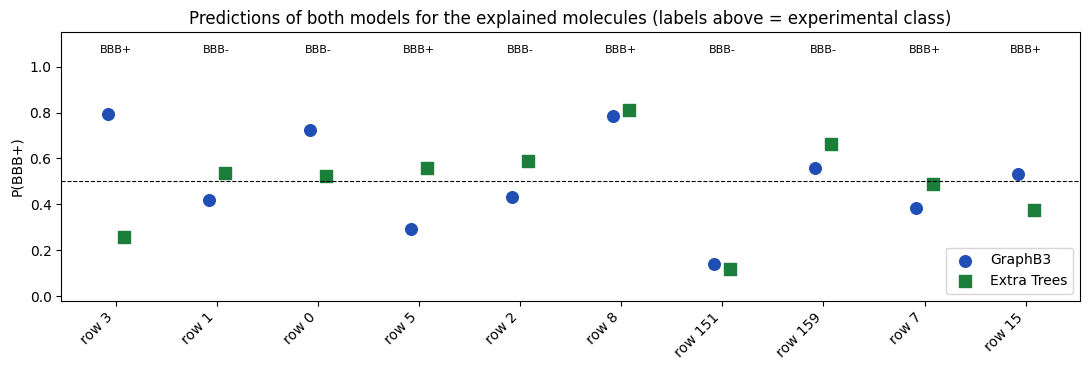

In [45]:
def _fmt_atoms(r, k=3):
    t = atom_table(r).sort_values("importance_raw", ascending=False).head(k); return ", ".join(f"{e}{i} ({s:.2f})" for e, i, s in zip(t["element"], t["atom_idx"], t["importance_raw"]))
def _fmt_bonds(r, k=3):
    t = bond_table(r).sort_values("importance_raw", ascending=False).head(k); return ", ".join(f"b{b} {a} ({s:.2f})" for b, a, s in zip(t["bond_idx"], t["atoms"], t["importance_raw"])) if len(t) else "no bonds"
rows = []
for i, r in EXPLAIN_CACHE.items():
    pr = PRED_DF.iloc[i]; _, loc_i = et_local_sensitivity(i); ok = r["status"] == "ok"
    rows.append({"test_row": i, "mol_id": r["mol_id"], "true": CLASS_NAME[r["y_true"]], "GraphB3": f"{CLASS_NAME[int(pr['pred_graphb3'])]} ({pr['p_graphb3']:.2f})",
                 "Extra Trees": f"{CLASS_NAME[int(pr['pred_extratrees'])]} ({pr['p_extratrees']:.2f})", "labels agree": "yes" if pr["pred_graphb3"] == pr["pred_extratrees"] else "NO",
                 "GraphB3 top atoms (raw score)": _fmt_atoms(r) if ok else "n/a: " + r["error"], "GraphB3 top bonds (raw score)": _fmt_bonds(r) if ok else "n/a",
                 "Extra Trees top descriptors (change in P)": ", ".join(f"{d} ({c:+.2f})" for d, c in zip(loc_i["descriptor"].head(3), loc_i["change"].head(3)))})
CMP_EXPL = pd.DataFrame(rows); pd.set_option("display.max_colwidth", 120); display(CMP_EXPL)
if len(CMP_EXPL):
    print(f"Among these {len(CMP_EXPL)} illustrative molecules (chosen to include errors and disagreements, so NOT representative): labels agree on {int((CMP_EXPL['labels agree'] == 'yes').sum())}, disagree on {int((CMP_EXPL['labels agree'] == 'NO').sum())}.")
    fig, ax = plt.subplots(figsize=(max(6, 0.9 * len(CMP_EXPL) + 2), 3.8)); xs = np.arange(len(CMP_EXPL))
    ax.scatter(xs - .08, [PRED_DF.loc[i, "p_graphb3"] for i in CMP_EXPL["test_row"]], s=70, color=COL["GraphB3"], label="GraphB3")
    ax.scatter(xs + .08, [PRED_DF.loc[i, "p_extratrees"] for i in CMP_EXPL["test_row"]], s=70, marker="s", color=COL["Extra Trees"], label="Extra Trees")
    for x_, t_ in zip(xs, CMP_EXPL["true"]): ax.text(x_, 1.06, t_, ha="center", fontsize=8)
    ax.axhline(THRESHOLD, color="k", ls="--", lw=.8); ax.set_xticks(xs); ax.set_xticklabels([f"row {i}" for i in CMP_EXPL["test_row"]], rotation=45, ha="right"); ax.set_ylim(-0.02, 1.15)
    ax.set_ylabel("P(BBB+)"); ax.set_title("Predictions of both models for the explained molecules (labels above = experimental class)"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 15b. Wrong-prediction gallery in 3D, with explanations (checklist items 7 and 8)
Four groups of **test** molecules, each shown as a card with: the actual label, both models' predicted labels and probabilities, a green ✓ CORRECT / red ✗ WRONG badge per model, an interactive **3D structure** coloured by GraphB3's GNNExplainer atom and bond scores (same viewer as section 13), and a one-line explanation from each model (GraphB3's top atoms / bonds; Extra Trees' descriptors whose replacement by the training median changes P(BBB+) most).

| Group | Selection rule (most informative first) |
|---|---|
| **A. GraphB3 wrong, Extra Trees correct** | highest GraphB3 confidence in the wrong class |
| **B. Extra Trees wrong, GraphB3 correct** | highest Extra Trees confidence in the wrong class |
| **C. Both wrong** | highest confidence of the *less* sure model (confident shared errors; may be label problems) |
| **D. Disagreement (one says BBB+, the other BBB−)** | largest probability gap, skipping molecules already shown in A–C (in a two-class problem every disagreement is a single-model error, so D re-shows nothing but adds variety) |

`N_GALLERY` (settings cell) sets how many molecules per group; only molecules with 6–45 atoms are used so the 3D embedding is reliable. **Reading the cards:** highlights and descriptor changes describe what the *trained models* respond to; they do not prove why a molecule is or is not BBB-permeable, and neither explanation is used to decide which model is right — the experimental label does that.

In [46]:
GAL_ATOMS = np.array([TE_MOLS[i].GetNumAtoms() for i in CMP.test_row]); _ok_size = (GAL_ATOMS >= 6) & (GAL_ATOMS <= 45)
_c = CMP.assign(g_conf=(CMP.graphb3_prob - .5).abs() * 2, e_conf=(CMP.extratrees_prob - .5).abs() * 2, gap=(CMP.graphb3_prob - CMP.extratrees_prob).abs())
_c["both_conf"] = np.minimum(_c.g_conf, _c.e_conf)
_shown = set()
def _pick(mask, key, n):
    d = _c[mask & _ok_size & ~_c.test_row.isin(_shown)].sort_values(key, ascending=False).head(n); _shown.update(d.test_row.tolist()); return d.test_row.tolist()
GALLERY = {"A. GraphB3 wrong, Extra Trees correct": _pick(_c.category == CAT_G_WRONG, "g_conf", N_GALLERY),
           "B. Extra Trees wrong, GraphB3 correct": _pick(_c.category == CAT_E_WRONG, "e_conf", N_GALLERY),
           "C. Both models wrong": _pick(_c.category == CAT_BOTH_WRONG, "both_conf", N_GALLERY),
           "D. Disagreement (one BBB+, one BBB-)": _pick(~_c.models_agree, "gap", N_GALLERY)}
GALLERY_ROWS = pd.DataFrame([dict(group=g, **CMP.iloc[i][["test_row", "mol_id", "SMILES", "actual_label", "graphb3_pred_label", "graphb3_prob", "extratrees_pred_label", "extratrees_prob", "category"]].to_dict())
                             for g, ids in GALLERY.items() for i in ids])
GALLERY_ROWS.to_csv(OUT_DIR / "wrong_prediction_gallery.csv", index=False)
print({g: ids for g, ids in GALLERY.items()}); print(f"saved the gallery selection -> {OUT_DIR/'wrong_prediction_gallery.csv'}")

def _badge(ok):
    return ('<span style="background:#2e7d32;color:#fff;padding:2px 9px;border-radius:10px;font-weight:bold">&#10003; CORRECT</span>' if ok else
            '<span style="background:#c62828;color:#fff;padding:2px 9px;border-radius:10px;font-weight:bold">&#10007; WRONG</span>')
_BORDER = {CAT_BOTH_OK: "#2e7d32", CAT_G_WRONG: "#ef6c00", CAT_E_WRONG: "#ef6c00", CAT_BOTH_WRONG: "#c62828"}
def gallery_header(i, group):
    r = CMP.iloc[i]; e = html.escape
    return (f'<div style="font-family:sans-serif;font-size:13px;color:#222;background:#fff;border:2px solid {_BORDER[r.category]};border-radius:8px;padding:9px 14px;max-width:780px;line-height:1.6;margin-top:14px">'
            f'<b>{e(group)}</b> &middot; test row {i} &middot; id <b>{e(str(r.mol_id))}</b><br>SMILES: <code style="word-break:break-all">{e(r.SMILES)}</code><br>'
            f'Actual label: <b>{CLASS_NAME[int(r.actual_label)]}</b><br>'
            f'<b>GraphB3</b> predicted <b>{CLASS_NAME[int(r.graphb3_pred_label)]}</b> (P(BBB+) = {r.graphb3_prob:.3f}) {_badge(r.graphb3_correct)}<br>'
            f'<b>Extra Trees</b> predicted <b>{CLASS_NAME[int(r.extratrees_pred_label)]}</b> (P(BBB+) = {r.extratrees_prob:.3f}) {_badge(r.extratrees_correct)}<br>'
            f'<span style="color:#555">category: {e(r.category)}</span></div>')

def show_gallery_molecule(i, group, with_legend=False):
    display(HTML(gallery_header(i, group)))
    res = EXPLAIN_CACHE.get(i)
    if res is None: res = explain_test_molecule(i); EXPLAIN_CACHE[i] = res
    if res["status"] != "ok":
        display(HTML(f'<div style="font-family:sans-serif;color:#c62828">No GraphB3 explanation available for row {i}: {html.escape(res["error"])}</div>')); return
    shown = False
    if HAVE_PY3DMOL:
        try: build_3d_viewer(res, 700, 460).show(); shown = True
        except Exception as exc: FAILURES.append(dict(test_row=i, mol_id=res["mol_id"], stage="gallery 3D", error=f"{type(exc).__name__}: {exc}"))
    if not shown: display(draw_explanation_2d(res, 480))
    if with_legend: display(HTML(legend_html(res)))
    _, loc_i = et_local_sensitivity(i); top = loc_i.head(3)
    et_txt = "; ".join(f"{d} = {v:.2f} (P changes {c:+.2f} if set to the training median {m:.2f})" for d, v, c, m in zip(top["descriptor"], top["value"], top["change"], top["training median"]))
    display(HTML('<div style="font-family:sans-serif;font-size:12.5px;color:#222;max-width:780px;border-left:4px solid #999;padding:4px 10px;background:#fafafa">'
                 f'<b>GraphB3 top atoms</b> (raw node-mask score): {html.escape(_fmt_atoms(res))}<br><b>GraphB3 top bonds</b>: {html.escape(_fmt_bonds(res))}<br>'
                 f'<b>Extra Trees top descriptors</b>: {html.escape(et_txt)}</div>'))

{'A. GraphB3 wrong, Extra Trees correct': [1509, 1441, 657], 'B. Extra Trees wrong, GraphB3 correct': [394, 1605, 336], 'C. Both models wrong': [709, 886, 1208], 'D. Disagreement (one BBB+, one BBB-)': [995, 423, 871]}
saved the gallery selection -> bbb_outputs/wrong_prediction_gallery.csv


### Group A. GraphB3 wrong, Extra Trees correct

In [47]:
_g = "A. GraphB3 wrong, Extra Trees correct"
if not GALLERY[_g]: print("no molecules in this group (after the size filter).")
for _k, _i in enumerate(GALLERY[_g]): show_gallery_molecule(_i, _g, with_legend=(_k == 0))

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Atom importance (sphere colour & size),low (0)raw 0.002high (1)raw 0.323
Bond importance (cylinder colour & thickness),low (0)raw 0.001high (1)raw 0.999


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Group B. Extra Trees wrong, GraphB3 correct

In [48]:
_g = "B. Extra Trees wrong, GraphB3 correct"
if not GALLERY[_g]: print("no molecules in this group (after the size filter).")
for _k, _i in enumerate(GALLERY[_g]): show_gallery_molecule(_i, _g, with_legend=(_k == 0))

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Atom importance (sphere colour & size),low (0)raw 0.003high (1)raw 0.219
Bond importance (cylinder colour & thickness),low (0)raw 0.001high (1)raw 0.999


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Group C. Both models wrong

In [49]:
_g = "C. Both models wrong"
if not GALLERY[_g]: print("no molecules in this group (after the size filter).")
for _k, _i in enumerate(GALLERY[_g]): show_gallery_molecule(_i, _g, with_legend=(_k == 0))

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Atom importance (sphere colour & size),low (0)raw 0.003high (1)raw 0.673
Bond importance (cylinder colour & thickness),low (0)raw 0.001high (1)raw 0.999


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Group D. Disagreement (one BBB+, one BBB-)

In [50]:
_g = "D. Disagreement (one BBB+, one BBB-)"
if not GALLERY[_g]: print("no molecules in this group (after the size filter).")
for _k, _i in enumerate(GALLERY[_g]): show_gallery_molecule(_i, _g, with_legend=(_k == 0))

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Atom importance (sphere colour & size),low (0)raw 0.005high (1)raw 0.212
Bond importance (cylinder colour & thickness),low (0)raw 0.001high (1)raw 0.999


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 16. Limitations, conclusions and reproducibility notes

**What the measured results do and do not show.** Section 10 reports the metric differences, whether the two models make different errors, and the McNemar / bootstrap assessment, all computed from *this* run; section 10's last cell states what those checks support. Please read conclusions from there and not from this text.

**Limitations**
* **One split.** All numbers come from one train/validation/test split, one GraphB3 training run (unless `RUN_MULTI_SEED` is used) and one tuning run. A different split or seed can change the metrics by amounts comparable to small differences between models. The bootstrap and McNemar test cover test-set sampling noise only; they do not cover training randomness and are not corrected for multiple comparisons.
* **Reused checkpoints.** If a checkpoint was reused, its training provenance is not verifiable from the file. `FORCE_RETRAIN_GRAPHB3 = True` gives a self-contained run.
* **Labels and domain.** BBB labels are literature-derived and noisy; active transport, efflux, and metabolism are not represented by either input type. Test molecules outside the training descriptor range (clipped for Extra Trees) are a distribution-shift risk.
* **Duplicates / leakage.** Duplicates and train/test overlap are reported (section 4) and handled only if `DROP_DUPLICATES = True`; the overlap sensitivity in section 10 shows whether it matters.
* **Explanations describe models, not chemistry.** GNNExplainer is a stochastic optimisation (one run per molecule, seeded); scores depend on the explainer's sparsity regularisation, are min–max-normalised for display, and are *not* probabilities or causal effects. Atom scores aggregate 33 feature-level mask values (`ATOM_AGG`); bond scores average two directed edges. Permutation importance depends on the held-out sample and is affected by correlated descriptors; built-in importance is computed on training data; the per-molecule sensitivity is an occlusion relative to an arbitrary median reference.
* **3D view.** The conformer is a single ETKDG/MMFF structure (or a flat 2D fallback, which is reported); GraphB3 never uses 3D coordinates, and the geometry is not evidence of a binding or transport mechanism.
* **Illustrative molecules** are deliberately chosen to include errors and disagreements, so they are not a representative sample.

In [51]:
# ---------------------------------------------------------------- reproducibility record
import platform, sklearn, scipy, rdkit, torch_geometric
vers = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
        "matplotlib": matplotlib.__version__, "rdkit": rdkit.__version__, "torch": torch.__version__, "torch_geometric": torch_geometric.__version__}
if HAVE_PY3DMOL: import py3Dmol; vers["py3Dmol"] = py3Dmol.__version__
print("package versions:", vers)
print(f"seeds: split random_state=42 | GraphB3 training seed 0 (model init seed 565) | Extra Trees / search RANDOM_STATE={RANDOM_STATE} | CV shuffle seed 42 | explainer/conformer/bootstrap SEED={SEED} (explainer seed = SEED + test row)")
print(f"settings: EPOCHS={EPOCHS}, EXPLAINER_EPOCHS={EXPLAINER_EPOCHS}, N_ITER={N_ITER}, CV_FOLDS={CV_FOLDS}, PERM_REPEATS={PERM_REPEATS}, N_BOOT={N_BOOT}, THRESHOLD={THRESHOLD}, ATOM_AGG={ATOM_AGG}, DROP_DUPLICATES={DROP_DUPLICATES}, QUICK_TEST={QUICK_TEST}")
print(f"data: train {len(ytr)} | validation {len(yva)} | test {len(y_test)} | test fingerprint {TEST_FINGERPRINT} | GraphB3 trained in this session: {TRAIN_GRAPHB3} | checkpoint {MODEL_PATH}")

# ---------------------------------------------------------------- automatic integrity checks
checks = []
def check(name, cond): checks.append((name, bool(cond)))
check("both models scored the same number of test molecules", len(P_G) == len(P_ET) == len(y_test) == len(te_df) == len(PRED_DF))
check("test labels identical for GraphB3 graphs, Extra Trees and the prediction table", all(int(g.y.item()) == int(l) for g, l in zip(test_graphs, y_test)) and (PRED_DF["y_true"].values == y_test).all())
check("test set unchanged since the split verification (SMILES fingerprint)", hashlib.sha1("\n".join(te_df["SMILES"]).encode()).hexdigest()[:12] == TEST_FINGERPRINT)
check("both metric sets computed with the same y_test, threshold and positive class (BBB+ = 1)", RESULTS["GraphB3"]["TP"] + RESULTS["GraphB3"]["FN"] == RESULTS["Extra Trees"]["TP"] + RESULTS["Extra Trees"]["FN"] == int(y_test.sum()))
check("train / validation split is disjoint and equals the original split_data()", set(idx_tr).isdisjoint(idx_va) and all(a is b for a, b in zip(split_data(all_graphs)[1], val_graphs)))
check("Extra Trees importances carry the right descriptor names", len(ET_KEPT) == len(et_clf.feature_importances_) and set(ET_IMP_TABLE["descriptor"]) == set(NAMES) and list(X_te.columns) == NAMES)
check("Extra Trees positive-class probability taken from the column of class 1", list(et_clf.classes_)[POS_COL] == 1)
good = [r for r in EXPLAIN_CACHE.values() if r["status"] == "ok"]
def _graph_ok(r):
    try: verify_graph_matches_mol(test_graphs[r["test_idx"]], r["mol"]); return True
    except ValueError: return False
check("explained molecules: graph indices == RDKit indices", all(_graph_ok(r) for r in good))
check("explained molecules: one finite raw score per atom and per bond (no invented scores)", all(len(r["atom_raw"]) == r["mol"].GetNumAtoms() and len(r["bond_raw"]) == r["mol"].GetNumBonds() and np.all(np.isfinite(r["atom_raw"])) and np.all(np.isfinite(r["bond_raw"])) for r in good))
check("explained molecules: explained class == GraphB3 predicted class", all(r["explained_class"] == int(PRED_DF.loc[r["test_idx"], "pred_graphb3"]) for r in good))
check("3D viewer scores = stored explanation scores (viewer reads res['atom_raw'] / res['bond_raw'] / the normalised arrays)", all(np.allclose(r["atom_norm"], normalize_minmax(r["atom_raw"])[0], equal_nan=True) and np.allclose(r["bond_norm"], normalize_minmax(r["bond_raw"])[0], equal_nan=True) for r in good))
print()
for n, ok_ in checks: print(("PASS  " if ok_ else "FAIL  ") + n)
print(f"\nmolecules explained successfully: {len(good)} of {len(EXPLAIN_CACHE)} | recorded failures: {len(FAILURES)}")
assert all(ok_ for _, ok_ in checks), "At least one integrity check FAILED - see the list above."
print("ALL INTEGRITY CHECKS PASSED")

package versions: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'rdkit': '2026.09.1', 'torch': '2.11.0+cpu', 'torch_geometric': '2.8.1', 'py3Dmol': '2.5.5'}
seeds: split random_state=42 | GraphB3 training seed 0 (model init seed 565) | Extra Trees / search RANDOM_STATE=0 | CV shuffle seed 42 | explainer/conformer/bootstrap SEED=0 (explainer seed = SEED + test row)
settings: EPOCHS=100, EXPLAINER_EPOCHS=2000, N_ITER=8, CV_FOLDS=5, PERM_REPEATS=10, N_BOOT=1000, THRESHOLD=0.5, ATOM_AGG=mean_active, DROP_DUPLICATES=False, QUICK_TEST=False
data: train 4821 | validation 1206 | test 1771 | test fingerprint 37546977fe5b | GraphB3 trained in this session: True | checkpoint bbb_outputs/best_model.pt

PASS  both models scored the same number of test molecules
PASS  test labels identical for GraphB3 graphs, Extra Trees and the prediction table
PASS  test set unchanged since the split verification (SMILES fingerprint)
